In [1]:

import nflreadpy as nfl
import polars as pl

# Load weekly NFL player statistics
player_stats = nfl.load_player_stats(
    seasons=[2022, 2023, 2024, 2025],
    summary_level="week"
)

# Examine the dataset
print("Dataset shape:", player_stats.shape)

print("\nColumn names:")
print(player_stats.columns)

print("\nFirst five rows:")
print(player_stats.head())


Dataset shape: (75879, 150)

Column names:
['player_id', 'player_name', 'player_display_name', 'position', 'position_group', 'headshot_url', 'season', 'week', 'season_type', 'game_id', 'team', 'opponent_team', 'completions', 'attempts', 'passing_yards', 'passing_tds', 'passing_interceptions', 'sacks_suffered', 'sack_yards_lost', 'sack_fumbles', 'sack_fumbles_lost', 'passing_air_yards', 'passing_yards_after_catch', 'passing_first_downs', 'passing_epa', 'passing_cpoe', 'passing_2pt_conversions', 'pacr', 'passing_10', 'passing_16', 'passing_20', 'passing_40', 'carries', 'rushing_yards', 'rushing_tds', 'rushing_fumbles', 'rushing_fumbles_lost', 'rushing_first_downs', 'rushing_epa', 'rushing_2pt_conversions', 'rushing_10', 'rushing_12', 'rushing_20', 'rushing_40', 'receptions', 'targets', 'receiving_yards', 'receiving_tds', 'receiving_fumbles', 'receiving_fumbles_lost', 'receiving_air_yards', 'receiving_yards_after_catch', 'receiving_first_downs', 'receiving_epa', 'receiving_2pt_conversions

In [2]:

# Select the columns we need to investigate
scoring_data = player_stats.select([
    "player_display_name",
    "position",
    "season",
    "week",
    "passing_yards",
    "passing_tds",
    "passing_interceptions",
    "rushing_yards",
    "rushing_tds",
    "receptions",
    "receiving_yards",
    "receiving_tds",
    "fumbles_lost_total",
    "fantasy_points",
    "fantasy_points_ppr"
])

# Display the first 10 rows
print(scoring_data.head(10))


shape: (10, 15)
┌─────────────┬──────────┬────────┬──────┬───┬─────────────┬─────────────┬────────────┬────────────┐
│ player_disp ┆ position ┆ season ┆ week ┆ … ┆ receiving_t ┆ fumbles_los ┆ fantasy_po ┆ fantasy_po │
│ lay_name    ┆ ---      ┆ ---    ┆ ---  ┆   ┆ ds          ┆ t_total     ┆ ints       ┆ ints_ppr   │
│ ---         ┆ str      ┆ i32    ┆ i32  ┆   ┆ ---         ┆ ---         ┆ ---        ┆ ---        │
│ str         ┆          ┆        ┆      ┆   ┆ i32         ┆ i32         ┆ f64        ┆ f64        │
╞═════════════╪══════════╪════════╪══════╪═══╪═════════════╪═════════════╪════════════╪════════════╡
│ Tom Brady   ┆ QB       ┆ 2022   ┆ 1    ┆ … ┆ 0           ┆ 0           ┆ 10.38      ┆ 10.38      │
│ Andy Lee    ┆ P        ┆ 2022   ┆ 1    ┆ … ┆ 0           ┆ 0           ┆ 0.0        ┆ 0.0        │
│ Robbie      ┆ K        ┆ 2022   ┆ 1    ┆ … ┆ 0           ┆ 0           ┆ 0.0        ┆ 0.0        │
│ Gould       ┆          ┆        ┆      ┆   ┆             ┆             ┆ 

In [3]:

# Create our own PPR fantasy points variable
player_stats = player_stats.with_columns(
    (
        (pl.col("passing_yards") * 0.04) +
        (pl.col("passing_tds") * 4) -
        (pl.col("passing_interceptions") * 2) +
        (pl.col("rushing_yards") * 0.1) +
        (pl.col("rushing_tds") * 6) +
        (pl.col("receptions") * 1) +
        (pl.col("receiving_yards") * 0.1) +
        (pl.col("receiving_tds") * 6) -
        (pl.col("fumbles_lost_total") * 2) +
        (
            pl.col("passing_2pt_conversions") +
            pl.col("rushing_2pt_conversions") +
            pl.col("receiving_2pt_conversions")
        ) * 2
    ).alias("our_fantasy_points_ppr")
)

# Display our new variable
print(
    player_stats.select([
        "player_display_name",
        "position",
        "fantasy_points_ppr",
        "our_fantasy_points_ppr"
    ]).head(10)
)


shape: (10, 4)
┌─────────────────────┬──────────┬────────────────────┬────────────────────────┐
│ player_display_name ┆ position ┆ fantasy_points_ppr ┆ our_fantasy_points_ppr │
│ ---                 ┆ ---      ┆ ---                ┆ ---                    │
│ str                 ┆ str      ┆ f64                ┆ f64                    │
╞═════════════════════╪══════════╪════════════════════╪════════════════════════╡
│ Tom Brady           ┆ QB       ┆ 10.38              ┆ 10.38                  │
│ Andy Lee            ┆ P        ┆ 0.0                ┆ 0.0                    │
│ Robbie Gould        ┆ K        ┆ 0.0                ┆ 0.0                    │
│ Aaron Rodgers       ┆ QB       ┆ 3.7                ┆ 3.7                    │
│ Matt Prater         ┆ K        ┆ 0.0                ┆ 0.0                    │
│ Nick Folk           ┆ K        ┆ 0.0                ┆ 0.0                    │
│ Mason Crosby        ┆ K        ┆ 0.0                ┆ 0.0                    │
│ Matt Ryan  

In [4]:

# Calculate the difference between the two variables
player_stats = player_stats.with_columns(
    (
        pl.col("our_fantasy_points_ppr") -
        pl.col("fantasy_points_ppr")
    ).alias("fantasy_points_difference")
)

# Calculate the average absolute difference
average_difference = player_stats.select(
    pl.col("fantasy_points_difference").abs().mean()
)

# Count rows with differences
different_rows = player_stats.filter(
    pl.col("fantasy_points_difference").abs() > 0.001
)

print("Average absolute difference:", average_difference)
print("Number of rows with differences:", different_rows.height)

# Display examples of differences
print(
    different_rows.select([
        "player_display_name",
        "position",
        "fantasy_points_ppr",
        "our_fantasy_points_ppr",
        "fantasy_points_difference"
    ]).head(10)
)


Average absolute difference: shape: (1, 1)
┌───────────────────────────┐
│ fantasy_points_difference │
│ ---                       │
│ f64                       │
╞═══════════════════════════╡
│ 0.010438                  │
└───────────────────────────┘
Number of rows with differences: 241
shape: (10, 5)
┌─────────────────────┬──────────┬────────────────────┬──────────────────────┬─────────────────────┐
│ player_display_name ┆ position ┆ fantasy_points_ppr ┆ our_fantasy_points_p ┆ fantasy_points_diff │
│ ---                 ┆ ---      ┆ ---                ┆ pr                   ┆ erence              │
│ str                 ┆ str      ┆ f64                ┆ ---                  ┆ ---                 │
│                     ┆          ┆                    ┆ f64                  ┆ f64                 │
╞═════════════════════╪══════════╪════════════════════╪══════════════════════╪═════════════════════╡
│ Kyle Philips        ┆ WR       ┆ 12.6               ┆ 10.6                 ┆ -2.0      

In [5]:

player_stats = player_stats.with_columns(
    (
        (pl.col("passing_yards") * 0.04) +
        (pl.col("passing_tds") * 4) -
        (pl.col("passing_interceptions") * 2) +
        (pl.col("rushing_yards") * 0.1) +
        (pl.col("rushing_tds") * 6) +
        (pl.col("receiving_yards") * 0.1) +
        (pl.col("receiving_tds") * 6) +
        (pl.col("special_teams_tds") * 6) +
        (pl.col("receptions") * 1) +
        (
            pl.col("passing_2pt_conversions") +
            pl.col("rushing_2pt_conversions") +
            pl.col("receiving_2pt_conversions")
        ) * 2 -
        (
            pl.col("sack_fumbles_lost") +
            pl.col("rushing_fumbles_lost") +
            pl.col("receiving_fumbles_lost")
        ) * 2
    ).alias("our_fantasy_points_ppr")
)

# Validate our new calculation
player_stats = player_stats.with_columns(
    (
        pl.col("our_fantasy_points_ppr") -
        pl.col("fantasy_points_ppr")
    ).alias("fantasy_points_difference")
)

print(
    "Average absolute difference:",
    player_stats.select(
        pl.col("fantasy_points_difference").abs().mean()
    )
)

print(
    "Rows with differences:",
    player_stats.filter(
        pl.col("fantasy_points_difference").abs() > 0.001
    ).height
)


Average absolute difference: shape: (1, 1)
┌───────────────────────────┐
│ fantasy_points_difference │
│ ---                       │
│ f64                       │
╞═══════════════════════════╡
│ 2.1194e-17                │
└───────────────────────────┘
Rows with differences: 0


In [6]:

# Keep only the four primary fantasy positions
fantasy_players = player_stats.filter(
    pl.col("position").is_in(["QB", "RB", "WR", "TE"])
)

# Check our new dataset
print("Original dataset:", player_stats.shape)
print("Fantasy player dataset:", fantasy_players.shape)

# Count players by position
print(
    fantasy_players.group_by("position")
    .agg(pl.len().alias("total_rows"))
    .sort("position")
)


Original dataset: (75879, 152)
Fantasy player dataset: (24616, 152)
shape: (4, 2)
┌──────────┬────────────┐
│ position ┆ total_rows │
│ ---      ┆ ---        │
│ str      ┆ u32        │
╞══════════╪════════════╡
│ QB       ┆ 2741       │
│ RB       ┆ 6451       │
│ TE       ┆ 5123       │
│ WR       ┆ 10301      │
└──────────┴────────────┘


In [7]:

# Sort players by their identity and game chronology
fantasy_players = fantasy_players.sort([
    "player_id",
    "season",
    "week"
])

# Check one player's weekly history
sample_player = fantasy_players.filter(
    pl.col("player_display_name") == "Christian McCaffrey"
)

print(
    sample_player.select([
        "player_display_name",
        "season",
        "week",
        "fantasy_points_ppr",
        "targets",
        "carries",
        "receptions"
    ])
)


shape: (62, 7)
┌─────────────────────┬────────┬──────┬────────────────────┬─────────┬─────────┬────────────┐
│ player_display_name ┆ season ┆ week ┆ fantasy_points_ppr ┆ targets ┆ carries ┆ receptions │
│ ---                 ┆ ---    ┆ ---  ┆ ---                ┆ ---     ┆ ---     ┆ ---        │
│ str                 ┆ i32    ┆ i32  ┆ f64                ┆ i32     ┆ i32     ┆ i32        │
╞═════════════════════╪════════╪══════╪════════════════════╪═════════╪═════════╪════════════╡
│ Christian McCaffrey ┆ 2022   ┆ 1    ┆ 15.7               ┆ 5       ┆ 10      ┆ 4          │
│ Christian McCaffrey ┆ 2022   ┆ 2    ┆ 16.8               ┆ 5       ┆ 15      ┆ 4          │
│ Christian McCaffrey ┆ 2022   ┆ 3    ┆ 13.5               ┆ 4       ┆ 25      ┆ 2          │
│ Christian McCaffrey ┆ 2022   ┆ 4    ┆ 25.8               ┆ 9       ┆ 8       ┆ 9          │
│ Christian McCaffrey ┆ 2022   ┆ 5    ┆ 23.4               ┆ 12      ┆ 14      ┆ 7          │
│ …                   ┆ …      ┆ …    ┆ …    

In [8]:
print(fantasy_players["season_type"].unique())

shape: (2,)
Series: 'season_type' [str]
[
	"REG"
	"POST"
]


In [9]:
fantasy_players = fantasy_players.filter(
    pl.col("season_type") == "REG"
)

print(fantasy_players.shape)

(23510, 152)


In [10]:
sample_player = fantasy_players.filter(
    pl.col("player_display_name") == "Christian McCaffrey"
)

print(
    sample_player.select([
        "player_display_name",
        "season",
        "week",
        "fantasy_points_ppr",
        "targets",
        "carries",
        "receptions"
    ])
)

shape: (54, 7)
┌─────────────────────┬────────┬──────┬────────────────────┬─────────┬─────────┬────────────┐
│ player_display_name ┆ season ┆ week ┆ fantasy_points_ppr ┆ targets ┆ carries ┆ receptions │
│ ---                 ┆ ---    ┆ ---  ┆ ---                ┆ ---     ┆ ---     ┆ ---        │
│ str                 ┆ i32    ┆ i32  ┆ f64                ┆ i32     ┆ i32     ┆ i32        │
╞═════════════════════╪════════╪══════╪════════════════════╪═════════╪═════════╪════════════╡
│ Christian McCaffrey ┆ 2022   ┆ 1    ┆ 15.7               ┆ 5       ┆ 10      ┆ 4          │
│ Christian McCaffrey ┆ 2022   ┆ 2    ┆ 16.8               ┆ 5       ┆ 15      ┆ 4          │
│ Christian McCaffrey ┆ 2022   ┆ 3    ┆ 13.5               ┆ 4       ┆ 25      ┆ 2          │
│ Christian McCaffrey ┆ 2022   ┆ 4    ┆ 25.8               ┆ 9       ┆ 8       ┆ 9          │
│ Christian McCaffrey ┆ 2022   ┆ 5    ┆ 23.4               ┆ 12      ┆ 14      ┆ 7          │
│ …                   ┆ …      ┆ …    ┆ …    

In [11]:
fantasy_players = fantasy_players.sort([
    "player_id",
    "season",
    "week"
])

fantasy_players = fantasy_players.with_columns(
    pl.col("fantasy_points_ppr")
    .shift(1)
    .over(["player_id", "season"])
    .alias("previous_week_fantasy_points")
)


In [12]:
print(
    fantasy_players
    .filter(
        pl.col("player_display_name") == "Christian McCaffrey"
    )
    .select([
        "season",
        "week",
        "fantasy_points_ppr",
        "previous_week_fantasy_points"
    ])
    .head(10)
)

shape: (10, 4)
┌────────┬──────┬────────────────────┬──────────────────────────────┐
│ season ┆ week ┆ fantasy_points_ppr ┆ previous_week_fantasy_points │
│ ---    ┆ ---  ┆ ---                ┆ ---                          │
│ i32    ┆ i32  ┆ f64                ┆ f64                          │
╞════════╪══════╪════════════════════╪══════════════════════════════╡
│ 2022   ┆ 1    ┆ 15.7               ┆ null                         │
│ 2022   ┆ 2    ┆ 16.8               ┆ 15.7                         │
│ 2022   ┆ 3    ┆ 13.5               ┆ 16.8                         │
│ 2022   ┆ 4    ┆ 25.8               ┆ 13.5                         │
│ 2022   ┆ 5    ┆ 23.4               ┆ 25.8                         │
│ 2022   ┆ 6    ┆ 22.8               ┆ 23.4                         │
│ 2022   ┆ 7    ┆ 8.2                ┆ 22.8                         │
│ 2022   ┆ 8    ┆ 40.26              ┆ 8.2                          │
│ 2022   ┆ 10   ┆ 17.7               ┆ 40.26                        │
│ 202

In [13]:

fantasy_players = fantasy_players.with_columns([
    pl.col("fantasy_points_ppr")
    .shift(1)
    .over(["player_id", "season"])
    .alias("previous_week_fantasy_points"),

    pl.col("fantasy_points_ppr")
    .shift(1)
    .rolling_mean(window_size=3)
    .over(["player_id", "season"])
    .alias("average_previous_3_games"),

    pl.col("targets")
    .shift(1)
    .rolling_mean(window_size=3)
    .over(["player_id", "season"])
    .alias("average_previous_3_targets"),

    pl.col("carries")
    .shift(1)
    .rolling_mean(window_size=3)
    .over(["player_id", "season"])
    .alias("average_previous_3_carries")
])


In [14]:

sample_player = fantasy_players.filter(
    pl.col("player_display_name") == "Christian McCaffrey"
)

print(
    sample_player.select([
        "season",
        "week",
        "fantasy_points_ppr",
        "previous_week_fantasy_points",
        "average_previous_3_games",
        "average_previous_3_targets",
        "average_previous_3_carries"
    ]).head(10)
)


shape: (10, 7)
┌────────┬──────┬────────────────┬────────────────┬────────────────┬───────────────┬───────────────┐
│ season ┆ week ┆ fantasy_points ┆ previous_week_ ┆ average_previo ┆ average_previ ┆ average_previ │
│ ---    ┆ ---  ┆ _ppr           ┆ fantasy_points ┆ us_3_games     ┆ ous_3_targets ┆ ous_3_carries │
│ i32    ┆ i32  ┆ ---            ┆ ---            ┆ ---            ┆ ---           ┆ ---           │
│        ┆      ┆ f64            ┆ f64            ┆ f64            ┆ f64           ┆ f64           │
╞════════╪══════╪════════════════╪════════════════╪════════════════╪═══════════════╪═══════════════╡
│ 2022   ┆ 1    ┆ 15.7           ┆ null           ┆ null           ┆ null          ┆ null          │
│ 2022   ┆ 2    ┆ 16.8           ┆ 15.7           ┆ null           ┆ null          ┆ null          │
│ 2022   ┆ 3    ┆ 13.5           ┆ 16.8           ┆ null           ┆ null          ┆ null          │
│ 2022   ┆ 4    ┆ 25.8           ┆ 13.5           ┆ 15.333333      ┆ 4.66666

In [15]:

print(fantasy_players.columns)


['player_id', 'player_name', 'player_display_name', 'position', 'position_group', 'headshot_url', 'season', 'week', 'season_type', 'game_id', 'team', 'opponent_team', 'completions', 'attempts', 'passing_yards', 'passing_tds', 'passing_interceptions', 'sacks_suffered', 'sack_yards_lost', 'sack_fumbles', 'sack_fumbles_lost', 'passing_air_yards', 'passing_yards_after_catch', 'passing_first_downs', 'passing_epa', 'passing_cpoe', 'passing_2pt_conversions', 'pacr', 'passing_10', 'passing_16', 'passing_20', 'passing_40', 'carries', 'rushing_yards', 'rushing_tds', 'rushing_fumbles', 'rushing_fumbles_lost', 'rushing_first_downs', 'rushing_epa', 'rushing_2pt_conversions', 'rushing_10', 'rushing_12', 'rushing_20', 'rushing_40', 'receptions', 'targets', 'receiving_yards', 'receiving_tds', 'receiving_fumbles', 'receiving_fumbles_lost', 'receiving_air_yards', 'receiving_yards_after_catch', 'receiving_first_downs', 'receiving_epa', 'receiving_2pt_conversions', 'receiving_10', 'receiving_16', 'receivi

In [16]:

# Additional statistics to use when predicting future games
historical_stats = [
    "receptions",
    "receiving_yards",
    "rushing_yards",
    "passing_yards",
    "attempts",
    "completions",
    "passing_tds",
    "receiving_tds",
    "rushing_tds",
    "passing_interceptions"
]

# Calculate the average of each statistic over the previous 3 games
fantasy_players = fantasy_players.with_columns([
    pl.col(stat)
    .shift(1)
    .rolling_mean(window_size=3)
    .over(["player_id", "season"])
    .alias(f"average_previous_3_{stat}")
    for stat in historical_stats
])

print(fantasy_players.shape)


(23510, 166)


In [17]:

print(
    fantasy_players.select([
        "player_display_name",
        "position",
        "season",
        "week",
        "fantasy_points_ppr",
        "previous_week_fantasy_points",
        "average_previous_3_games",
        "average_previous_3_targets",
        "average_previous_3_carries",
        "average_previous_3_receiving_yards",
        "average_previous_3_rushing_yards",
        "average_previous_3_passing_yards"
    ]).head(10)
)


shape: (10, 12)
┌─────────────┬──────────┬────────┬──────┬───┬─────────────┬─────────────┬────────────┬────────────┐
│ player_disp ┆ position ┆ season ┆ week ┆ … ┆ average_pre ┆ average_pre ┆ average_pr ┆ average_pr │
│ lay_name    ┆ ---      ┆ ---    ┆ ---  ┆   ┆ vious_3_car ┆ vious_3_rec ┆ evious_3_r ┆ evious_3_p │
│ ---         ┆ str      ┆ i32    ┆ i32  ┆   ┆ ries        ┆ eiving_y…   ┆ ushing_yar ┆ assing_yar │
│ str         ┆          ┆        ┆      ┆   ┆ ---         ┆ ---         ┆ …          ┆ …          │
│             ┆          ┆        ┆      ┆   ┆ f64         ┆ f64         ┆ ---        ┆ ---        │
│             ┆          ┆        ┆      ┆   ┆             ┆             ┆ f64        ┆ f64        │
╞═════════════╪══════════╪════════╪══════╪═══╪═════════════╪═════════════╪════════════╪════════════╡
│ Tom Brady   ┆ QB       ┆ 2022   ┆ 1    ┆ … ┆ null        ┆ null        ┆ null       ┆ null       │
│ Tom Brady   ┆ QB       ┆ 2022   ┆ 2    ┆ … ┆ null        ┆ null        ┆ 

In [18]:

# Numeric features based on previous games
feature_columns = [
    "week",
    "previous_week_fantasy_points",
    "average_previous_3_games",
    "average_previous_3_targets",
    "average_previous_3_carries"
]

# Add the additional historical statistics
feature_columns += [
    f"average_previous_3_{stat}"
    for stat in historical_stats
]

# Keep only the information needed for modeling
model_data = fantasy_players.select(
    feature_columns + [
        "position",
        "team",
        "opponent_team",
        "season",
        "fantasy_points_ppr"
    ]
)

# Remove rows with missing historical information
model_data = model_data.drop_nulls()

# Convert categorical variables into numerical columns
model_data = model_data.to_dummies(
    columns=["position", "team", "opponent_team"]
)

# Separate training and testing seasons
train_data = model_data.filter(
    pl.col("season") < 2025
)

test_data = model_data.filter(
    pl.col("season") == 2025
)

print("Full modeling dataset:", model_data.shape)
print("Training dataset:", train_data.shape)
print("Testing dataset:", test_data.shape)


Full modeling dataset: (16885, 85)
Training dataset: (12560, 85)
Testing dataset: (4325, 85)


In [19]:
print(model_data.head())
print(model_data.null_count())

shape: (5, 85)
┌──────┬─────────────┬────────────┬────────────┬───┬────────────┬────────────┬────────┬────────────┐
│ week ┆ previous_we ┆ average_pr ┆ average_pr ┆ … ┆ opponent_t ┆ opponent_t ┆ season ┆ fantasy_po │
│ ---  ┆ ek_fantasy_ ┆ evious_3_g ┆ evious_3_t ┆   ┆ eam_TEN    ┆ eam_WAS    ┆ ---    ┆ ints_ppr   │
│ i32  ┆ points      ┆ ames       ┆ argets     ┆   ┆ ---        ┆ ---        ┆ i32    ┆ ---        │
│      ┆ ---         ┆ ---        ┆ ---        ┆   ┆ u8         ┆ u8         ┆        ┆ f64        │
│      ┆ f64         ┆ f64        ┆ f64        ┆   ┆            ┆            ┆        ┆            │
╞══════╪═════════════╪════════════╪════════════╪═══╪════════════╪════════════╪════════╪════════════╡
│ 4    ┆ 14.74       ┆ 11.506667  ┆ 0.0        ┆ … ┆ 0          ┆ 0          ┆ 2022   ┆ 25.4       │
│ 5    ┆ 25.4        ┆ 16.513333  ┆ 0.0        ┆ … ┆ 0          ┆ 0          ┆ 2022   ┆ 19.74      │
│ 6    ┆ 19.74       ┆ 19.96      ┆ 0.0        ┆ … ┆ 0          ┆ 0         

In [20]:
print("Full dataset:", model_data.shape)
print("Training dataset (2022–2024):", train_data.shape)
print("Testing dataset (2025):", test_data.shape)

print("\nTraining seasons:")
print(train_data["season"].unique())

print("\nTesting seasons:")
print(test_data["season"].unique())

Full dataset: (16885, 85)
Training dataset (2022–2024): (12560, 85)
Testing dataset (2025): (4325, 85)

Training seasons:
shape: (3,)
Series: 'season' [i32]
[
	2022
	2023
	2024
]

Testing seasons:
shape: (1,)
Series: 'season' [i32]
[
	2025
]


In [21]:

import numpy as np
import polars as pl

from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 1. Separate input variables from the target
# Season is excluded because we are testing on a future season.
feature_names = [
    col for col in train_data.columns
    if col not in ["season", "fantasy_points_ppr"]
]

X_train = train_data.select(feature_names).to_numpy()
X_test = test_data.select(feature_names).to_numpy()

y_train = train_data["fantasy_points_ppr"].to_numpy()
y_test = test_data["fantasy_points_ppr"].to_numpy()

# 2. Create our three models
models = {
    "Baseline": DummyRegressor(strategy="mean"),

    "Linear Regression": LinearRegression(),

    "Random Forest": RandomForestRegressor(
        n_estimators=300,
        max_depth=15,
        min_samples_leaf=5,
        random_state=42,
        n_jobs=-1
    )
}

# 3. Train each model and evaluate its predictions
results = []
trained_models = {}
predictions = {}

for name, model in models.items():

    model.fit(X_train, y_train)

    predicted_points = model.predict(X_test)

    trained_models[name] = model
    predictions[name] = predicted_points

    mae = mean_absolute_error(y_test, predicted_points)

    rmse = np.sqrt(
        mean_squared_error(y_test, predicted_points)
    )

    r2 = r2_score(y_test, predicted_points)

    results.append({
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    })

# 4. Display model comparison
model_results = pl.DataFrame(results).sort("MAE")

print(model_results)


shape: (3, 4)
┌───────────────────┬──────────┬──────────┬──────────┐
│ Model             ┆ MAE      ┆ RMSE     ┆ R2       │
│ ---               ┆ ---      ┆ ---      ┆ ---      │
│ str               ┆ f64      ┆ f64      ┆ f64      │
╞═══════════════════╪══════════╪══════════╪══════════╡
│ Random Forest     ┆ 4.682765 ┆ 6.432989 ┆ 0.37277  │
│ Linear Regression ┆ 4.698223 ┆ 6.433435 ┆ 0.372684 │
│ Baseline          ┆ 6.494839 ┆ 8.128325 ┆ -0.00139 │
└───────────────────┴──────────┴──────────┴──────────┘


In [22]:

from sklearn.inspection import permutation_importance

# Measure the importance of each variable on unseen 2025 data
importance_results = permutation_importance(
    trained_models["Random Forest"],
    X_test,
    y_test,
    scoring="neg_mean_absolute_error",
    n_repeats=5,
    random_state=42,
    n_jobs=-1
)

# Organize the results
feature_importance = pl.DataFrame({
    "Feature": feature_names,
    "Importance": importance_results.importances_mean,
    "Std": importance_results.importances_std
}).sort("Importance", descending=True)

# Display the 20 most influential variables
print(feature_importance.head(20))


shape: (20, 3)
┌─────────────────────────────────┬────────────┬──────────┐
│ Feature                         ┆ Importance ┆ Std      │
│ ---                             ┆ ---        ┆ ---      │
│ str                             ┆ f64        ┆ f64      │
╞═════════════════════════════════╪════════════╪══════════╡
│ average_previous_3_games        ┆ 1.376908   ┆ 0.048033 │
│ average_previous_3_targets      ┆ 0.321192   ┆ 0.017769 │
│ average_previous_3_rushing_yar… ┆ 0.075774   ┆ 0.008031 │
│ previous_week_fantasy_points    ┆ 0.070915   ┆ 0.007945 │
│ average_previous_3_attempts     ┆ 0.058536   ┆ 0.006012 │
│ …                               ┆ …          ┆ …        │
│ opponent_team_TB                ┆ 0.002548   ┆ 0.001137 │
│ opponent_team_CAR               ┆ 0.002454   ┆ 0.001677 │
│ team_BUF                        ┆ 0.002412   ┆ 0.000717 │
│ opponent_team_JAX               ┆ 0.001999   ┆ 0.00205  │
│ team_SF                         ┆ 0.0019     ┆ 0.000972 │
└────────────────────────

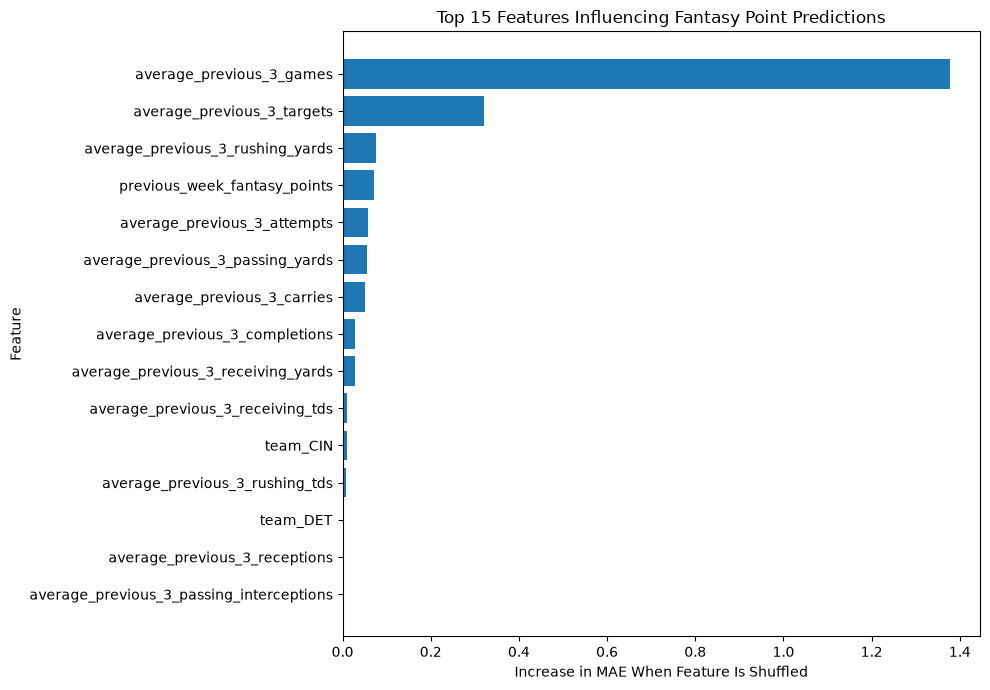

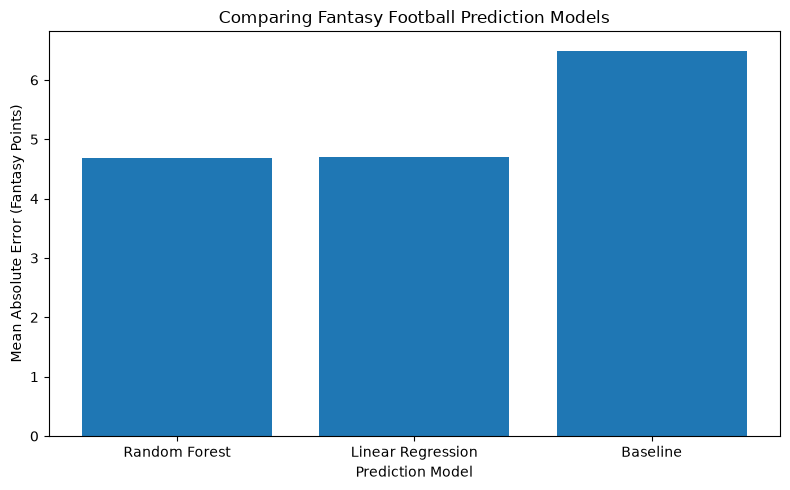

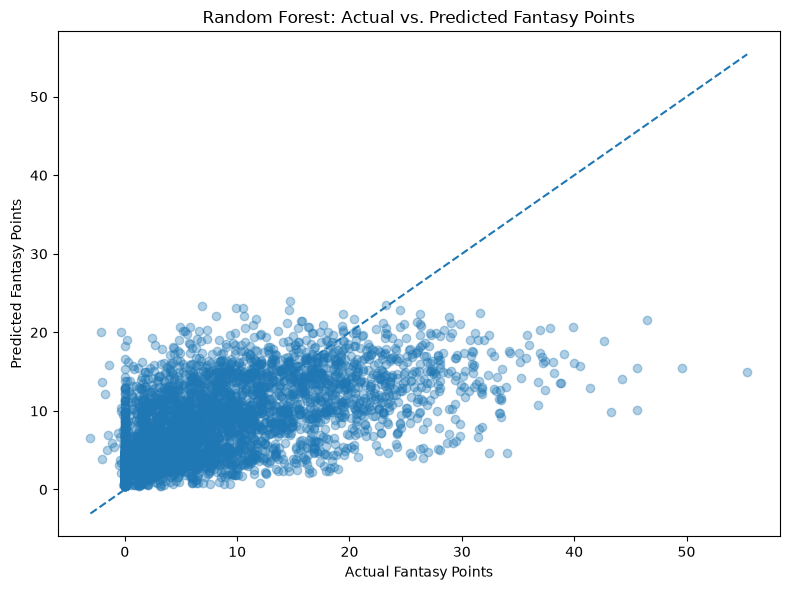

In [23]:
import matplotlib.pyplot as plt
import numpy as np

# --------------------------------
# GRAPH 1: FEATURE IMPORTANCE
# --------------------------------

top_features = feature_importance.head(15).sort("Importance")

plt.figure(figsize=(10, 7))

plt.barh(
    top_features["Feature"].to_list(),
    top_features["Importance"].to_list()
)

plt.xlabel("Increase in MAE When Feature Is Shuffled")
plt.ylabel("Feature")
plt.title("Top 15 Features Influencing Fantasy Point Predictions")
plt.tight_layout()
plt.show()


# --------------------------------
# GRAPH 2: MODEL COMPARISON
# --------------------------------

model_names = model_results["Model"].to_list()
mae_values = model_results["MAE"].to_list()

plt.figure(figsize=(8, 5))

plt.bar(model_names, mae_values)

plt.ylabel("Mean Absolute Error (Fantasy Points)")
plt.xlabel("Prediction Model")
plt.title("Comparing Fantasy Football Prediction Models")
plt.tight_layout()
plt.show()


# --------------------------------
# GRAPH 3: ACTUAL VS. PREDICTED
# --------------------------------

rf_predictions = predictions["Random Forest"]

plt.figure(figsize=(8, 6))

plt.scatter(y_test, rf_predictions, alpha=0.35)

# Perfect prediction reference line
minimum = min(y_test.min(), rf_predictions.min())
maximum = max(y_test.max(), rf_predictions.max())

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    linestyle="--"
)

plt.xlabel("Actual Fantasy Points")
plt.ylabel("Predicted Fantasy Points")
plt.title("Random Forest: Actual vs. Predicted Fantasy Points")
plt.tight_layout()
plt.show()

shape: (4, 3)
┌──────────┬─────────┬──────────┐
│ Position ┆ Players ┆ MAE      │
│ ---      ┆ ---     ┆ ---      │
│ str      ┆ i64     ┆ f64      │
╞══════════╪═════════╪══════════╡
│ TE       ┆ 909     ┆ 3.805892 │
│ WR       ┆ 1826    ┆ 4.520434 │
│ RB       ┆ 1152    ┆ 4.837597 │
│ QB       ┆ 438     ┆ 6.772101 │
└──────────┴─────────┴──────────┘


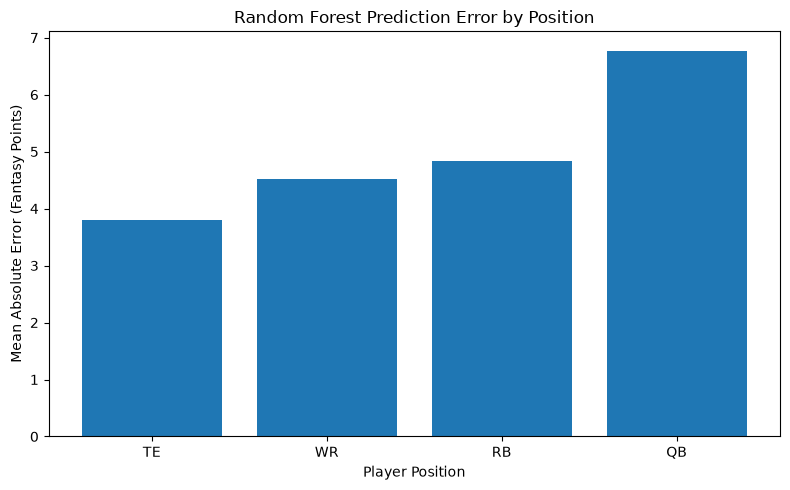

In [24]:

import numpy as np
import polars as pl
import matplotlib.pyplot as plt

# Identify each player's position from the one-hot columns
positions = np.select(
    [
        test_data["position_QB"].to_numpy() == 1,
        test_data["position_RB"].to_numpy() == 1,
        test_data["position_WR"].to_numpy() == 1,
        test_data["position_TE"].to_numpy() == 1
    ],
    ["QB", "RB", "WR", "TE"],
    default="Unknown"
)

# Create a table with actual points, predictions, and position
position_results = pl.DataFrame({
    "Position": positions,
    "Actual": y_test,
    "Predicted": predictions["Random Forest"]
})

# Calculate accuracy separately for each position
summary = []

for position in ["QB", "RB", "WR", "TE"]:
    group = position_results.filter(
        pl.col("Position") == position
    )

    actual = group["Actual"].to_numpy()
    predicted = group["Predicted"].to_numpy()

    mae = np.mean(np.abs(actual - predicted))

    summary.append({
        "Position": position,
        "Players": len(actual),
        "MAE": mae
    })

position_accuracy = pl.DataFrame(summary).sort("MAE")

print(position_accuracy)

# Create a graph
plt.figure(figsize=(8, 5))
plt.bar(
    position_accuracy["Position"].to_list(),
    position_accuracy["MAE"].to_list()
)

plt.title("Random Forest Prediction Error by Position")
plt.xlabel("Player Position")
plt.ylabel("Mean Absolute Error (Fantasy Points)")
plt.tight_layout()
plt.show()


In [25]:

position_error_summary = []

for position in ["QB", "RB", "WR", "TE"]:
    group = position_results.filter(
        pl.col("Position") == position
    )

    actual = group["Actual"].to_numpy()
    predicted = group["Predicted"].to_numpy()

    position_error_summary.append({
        "Position": position,
        "Average_Actual_Points": np.mean(actual),
        "Average_Predicted_Points": np.mean(predicted),
        "Actual_Standard_Deviation": np.std(actual),
        "MAE": np.mean(np.abs(actual - predicted)),
        "RMSE": np.sqrt(np.mean((actual - predicted) ** 2)),
        "Prediction_Bias": np.mean(predicted - actual)
    })

position_error_summary = pl.DataFrame(
    position_error_summary
)

print(position_error_summary)


shape: (4, 7)
┌──────────┬────────────────┬────────────────┬───────────────┬──────────┬──────────┬───────────────┐
│ Position ┆ Average_Actual ┆ Average_Predic ┆ Actual_Standa ┆ MAE      ┆ RMSE     ┆ Prediction_Bi │
│ ---      ┆ _Points        ┆ ted_Points     ┆ rd_Deviation  ┆ ---      ┆ ---      ┆ as            │
│ str      ┆ ---            ┆ ---            ┆ ---           ┆ f64      ┆ f64      ┆ ---           │
│          ┆ f64            ┆ f64            ┆ f64           ┆          ┆          ┆ f64           │
╞══════════╪════════════════╪════════════════╪═══════════════╪══════════╪══════════╪═══════════════╡
│ QB       ┆ 15.225479      ┆ 15.207263      ┆ 8.832059      ┆ 6.772101 ┆ 8.438551 ┆ -0.018216     │
│ RB       ┆ 8.343212       ┆ 8.186093       ┆ 8.559505      ┆ 4.837597 ┆ 6.791653 ┆ -0.157119     │
│ WR       ┆ 7.039387       ┆ 7.159767       ┆ 7.461878      ┆ 4.520434 ┆ 6.089943 ┆ 0.120381      │
│ TE       ┆ 6.274279       ┆ 6.119844       ┆ 6.442983      ┆ 3.805892 ┆ 5.4

In [26]:

from sklearn.inspection import permutation_importance

position_feature_results = []

for position in ["QB", "RB", "WR", "TE"]:

    # Find the test observations for this position
    mask = positions == position

    X_position = X_test[mask]
    y_position = y_test[mask]

    # Calculate feature importance for this position
    importance = permutation_importance(
        trained_models["Random Forest"],
        X_position,
        y_position,
        scoring="neg_mean_absolute_error",
        n_repeats=10,
        random_state=42,
        n_jobs=-1
    )

    # Save the top 8 features
    for index in np.argsort(
        importance.importances_mean
    )[::-1][:8]:

        position_feature_results.append({
            "Position": position,
            "Feature": feature_names[index],
            "Importance": importance.importances_mean[index]
        })

position_feature_importance = pl.DataFrame(
    position_feature_results
)

print(position_feature_importance)


shape: (32, 3)
┌──────────┬─────────────────────────────────┬────────────┐
│ Position ┆ Feature                         ┆ Importance │
│ ---      ┆ ---                             ┆ ---        │
│ str      ┆ str                             ┆ f64        │
╞══════════╪═════════════════════════════════╪════════════╡
│ QB       ┆ average_previous_3_games        ┆ 0.640815   │
│ QB       ┆ previous_week_fantasy_points    ┆ 0.103296   │
│ QB       ┆ average_previous_3_passing_yar… ┆ 0.037344   │
│ QB       ┆ average_previous_3_rushing_yar… ┆ 0.020579   │
│ QB       ┆ average_previous_3_attempts     ┆ 0.013731   │
│ …        ┆ …                               ┆ …          │
│ TE       ┆ previous_week_fantasy_points    ┆ 0.047973   │
│ TE       ┆ average_previous_3_receiving_t… ┆ 0.01794    │
│ TE       ┆ week                            ┆ 0.014549   │
│ TE       ┆ opponent_team_CIN               ┆ 0.00926    │
│ TE       ┆ team_SF                         ┆ 0.006228   │
└──────────┴─────────────

In [30]:
print(
    position_feature_importance.sort(
        ["Position", "Importance"],
        descending=[False, True]
    ).to_dicts()
)

[{'Position': 'QB', 'Feature': 'average_previous_3_games', 'Importance': 0.6408150012902605}, {'Position': 'QB', 'Feature': 'previous_week_fantasy_points', 'Importance': 0.10329635811031457}, {'Position': 'QB', 'Feature': 'average_previous_3_passing_yards', 'Importance': 0.037343990142836694}, {'Position': 'QB', 'Feature': 'average_previous_3_rushing_yards', 'Importance': 0.020578780161011424}, {'Position': 'QB', 'Feature': 'average_previous_3_attempts', 'Importance': 0.01373103481239033}, {'Position': 'QB', 'Feature': 'team_CIN', 'Importance': 0.013013761700163596}, {'Position': 'QB', 'Feature': 'average_previous_3_completions', 'Importance': 0.012943861931093892}, {'Position': 'QB', 'Feature': 'team_BUF', 'Importance': 0.011606410002248779}, {'Position': 'RB', 'Feature': 'average_previous_3_games', 'Importance': 1.5502484348182581}, {'Position': 'RB', 'Feature': 'average_previous_3_targets', 'Importance': 0.2559001741838817}, {'Position': 'RB', 'Feature': 'average_previous_3_rushing_

In [31]:

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

specialized_results = []

for position in ["QB", "RB", "WR", "TE"]:

    mask = positions == position

    X_train_position = X_train[
        train_data[
            f"position_{position}"
        ].to_numpy() == 1
    ]

    y_train_position = y_train[
        train_data[
            f"position_{position}"
        ].to_numpy() == 1
    ]

    X_test_position = X_test[mask]
    y_test_position = y_test[mask]

    # Train a separate model for this position
    position_model = RandomForestRegressor(
        n_estimators=300,
        max_depth=15,
        min_samples_leaf=5,
        random_state=42,
        n_jobs=-1
    )

    position_model.fit(
        X_train_position,
        y_train_position
    )

    predictions_position = position_model.predict(
        X_test_position
    )

    specialized_results.append({
        "Position": position,
        "Observations": len(y_test_position),
        "General_Model_MAE": mean_absolute_error(
            y_test_position,
            predictions["Random Forest"][mask]
        ),
        "Specialized_Model_MAE": mean_absolute_error(
            y_test_position,
            predictions_position
        ),
        "Specialized_Model_RMSE": np.sqrt(
            mean_squared_error(
                y_test_position,
                predictions_position
            )
        ),
        "Specialized_Model_R2": r2_score(
            y_test_position,
            predictions_position
        )
    })

specialized_comparison = pl.DataFrame(
    specialized_results
)

print(specialized_comparison)


shape: (4, 6)
┌──────────┬──────────────┬──────────────────┬─────────────────┬─────────────────┬─────────────────┐
│ Position ┆ Observations ┆ General_Model_MA ┆ Specialized_Mod ┆ Specialized_Mod ┆ Specialized_Mod │
│ ---      ┆ ---          ┆ E                ┆ el_MAE          ┆ el_RMSE         ┆ el_R2           │
│ str      ┆ i64          ┆ ---              ┆ ---             ┆ ---             ┆ ---             │
│          ┆              ┆ f64              ┆ f64             ┆ f64             ┆ f64             │
╞══════════╪══════════════╪══════════════════╪═════════════════╪═════════════════╪═════════════════╡
│ QB       ┆ 438          ┆ 6.772101         ┆ 6.797408        ┆ 8.479814        ┆ 0.078174        │
│ RB       ┆ 1152         ┆ 4.837597         ┆ 4.884673        ┆ 6.823204        ┆ 0.364553        │
│ WR       ┆ 1826         ┆ 4.520434         ┆ 4.53683         ┆ 6.089991        ┆ 0.333904        │
│ TE       ┆ 909          ┆ 3.805892         ┆ 3.858049        ┆ 5.463398    

In [32]:

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error
import polars as pl

# Define the four feature groups
feature_groups = {
    "Historical Performance": [
        "previous_week_fantasy_points",
        "average_previous_3_games"
    ],

    "Player Opportunity": [
        "average_previous_3_targets",
        "average_previous_3_carries",
        "average_previous_3_attempts",
        "average_previous_3_completions"
    ],

    "Statistical Production": [
        "average_previous_3_receptions",
        "average_previous_3_receiving_yards",
        "average_previous_3_rushing_yards",
        "average_previous_3_passing_yards",
        "average_previous_3_passing_tds",
        "average_previous_3_receiving_tds",
        "average_previous_3_rushing_tds",
        "average_previous_3_passing_interceptions"
    ],

    "Team Context": [
        col for col in feature_names
        if col == "week"
        or col.startswith("team_")
        or col.startswith("opponent_team_")
        or col.startswith("position_")
    ]
}

# Test each group independently and all groups together
experiments = {
    "All Feature Groups": list(feature_names)
}

for group_name, features in feature_groups.items():
    experiments[group_name] = features

results_by_group = []

for experiment_name, features in experiments.items():

    # Find the matching column positions
    feature_indices = [
        feature_names.index(feature)
        for feature in features
        if feature in feature_names
    ]

    X_train_group = X_train[:, feature_indices]
    X_test_group = X_test[:, feature_indices]

    model = RandomForestRegressor(
        n_estimators=300,
        max_depth=15,
        min_samples_leaf=5,
        random_state=42,
        n_jobs=-1
    )

    model.fit(X_train_group, y_train)

    group_predictions = model.predict(X_test_group)

    mae = mean_absolute_error(
        y_test,
        group_predictions
    )

    results_by_group.append({
        "Feature Group": experiment_name,
        "Number of Features": len(feature_indices),
        "MAE": mae
    })

feature_group_results = pl.DataFrame(
    results_by_group
).sort("MAE")

print(feature_group_results)


shape: (5, 3)
┌────────────────────────┬────────────────────┬──────────┐
│ Feature Group          ┆ Number of Features ┆ MAE      │
│ ---                    ┆ ---                ┆ ---      │
│ str                    ┆ i64                ┆ f64      │
╞════════════════════════╪════════════════════╪══════════╡
│ All Feature Groups     ┆ 83                 ┆ 4.682765 │
│ Player Opportunity     ┆ 4                  ┆ 4.786495 │
│ Statistical Production ┆ 8                  ┆ 4.80026  │
│ Historical Performance ┆ 2                  ┆ 4.937205 │
│ Team Context           ┆ 69                 ┆ 6.049894 │
└────────────────────────┴────────────────────┴──────────┘


In [33]:

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error
import polars as pl

ablation_results = []

# Train the full model first
full_model = RandomForestRegressor(
    n_estimators=300,
    max_depth=15,
    min_samples_leaf=5,
    random_state=42,
    n_jobs=-1
)

full_model.fit(X_train, y_train)
full_predictions = full_model.predict(X_test)

full_mae = mean_absolute_error(y_test, full_predictions)

ablation_results.append({
    "Experiment": "Full Model",
    "MAE": full_mae,
    "MAE_Increase": 0.0
})

# Remove one feature group at a time
for group_name, features in feature_groups.items():

    remaining_features = [
        feature for feature in feature_names
        if feature not in features
    ]

    feature_indices = [
        feature_names.index(feature)
        for feature in remaining_features
    ]

    X_train_reduced = X_train[:, feature_indices]
    X_test_reduced = X_test[:, feature_indices]

    model = RandomForestRegressor(
        n_estimators=300,
        max_depth=15,
        min_samples_leaf=5,
        random_state=42,
        n_jobs=-1
    )

    model.fit(X_train_reduced, y_train)

    reduced_predictions = model.predict(X_test_reduced)

    reduced_mae = mean_absolute_error(
        y_test,
        reduced_predictions
    )

    ablation_results.append({
        "Experiment": f"Without {group_name}",
        "MAE": reduced_mae,
        "MAE_Increase": reduced_mae - full_mae
    })

ablation_comparison = pl.DataFrame(
    ablation_results
).sort("MAE", descending=True)

print(ablation_comparison)


shape: (5, 3)
┌────────────────────────────────┬──────────┬──────────────┐
│ Experiment                     ┆ MAE      ┆ MAE_Increase │
│ ---                            ┆ ---      ┆ ---          │
│ str                            ┆ f64      ┆ f64          │
╞════════════════════════════════╪══════════╪══════════════╡
│ Without Team Context           ┆ 4.740521 ┆ 0.057756     │
│ Without Player Opportunity     ┆ 4.737107 ┆ 0.054342     │
│ Without Historical Performance ┆ 4.694508 ┆ 0.011743     │
│ Without Statistical Production ┆ 4.690713 ┆ 0.007948     │
│ Full Model                     ┆ 4.682765 ┆ 0.0          │
└────────────────────────────────┴──────────┴──────────────┘


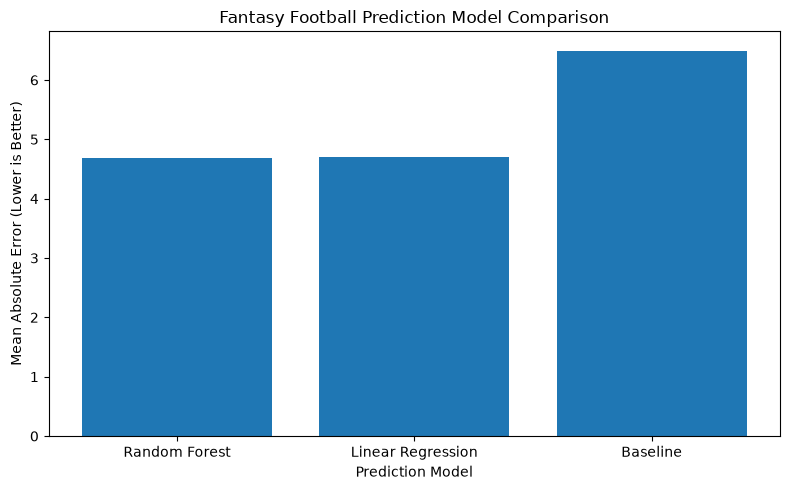

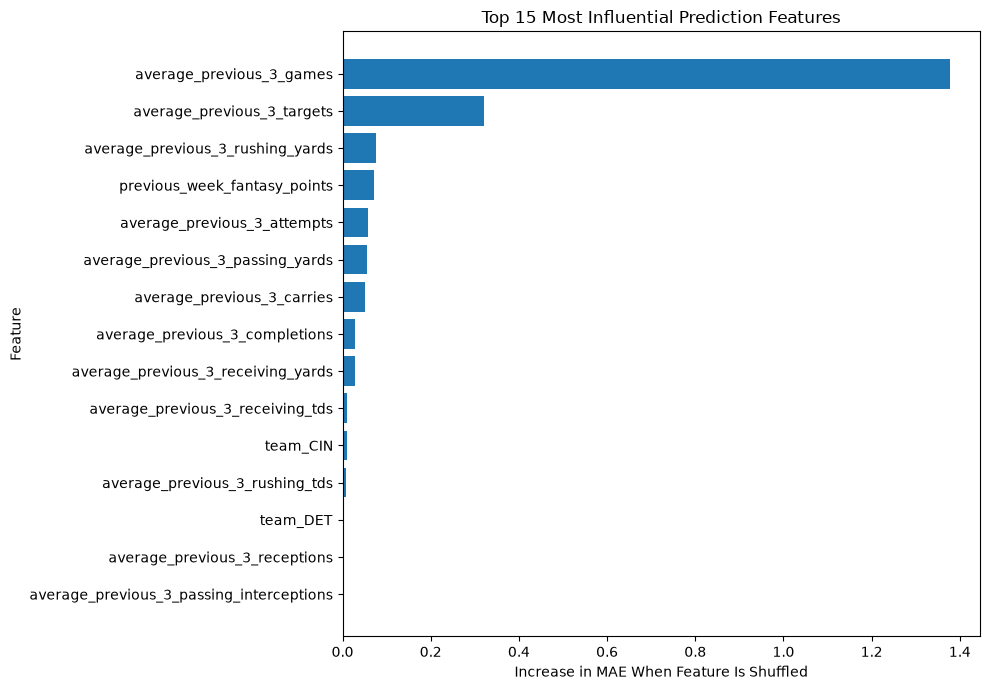

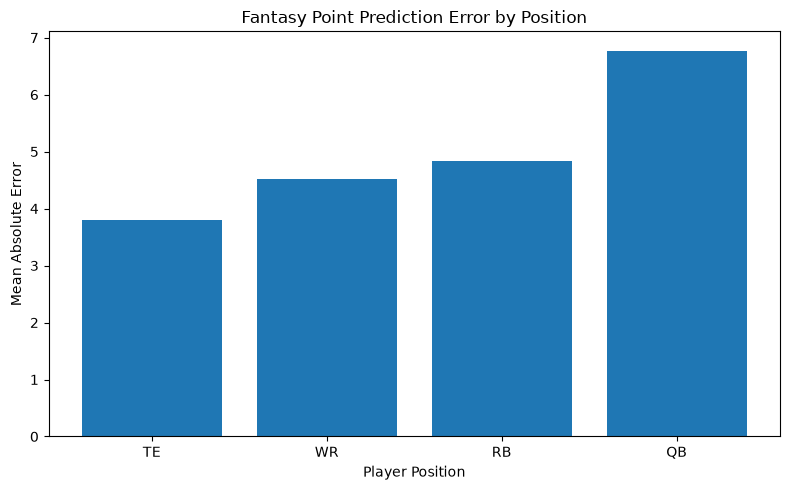

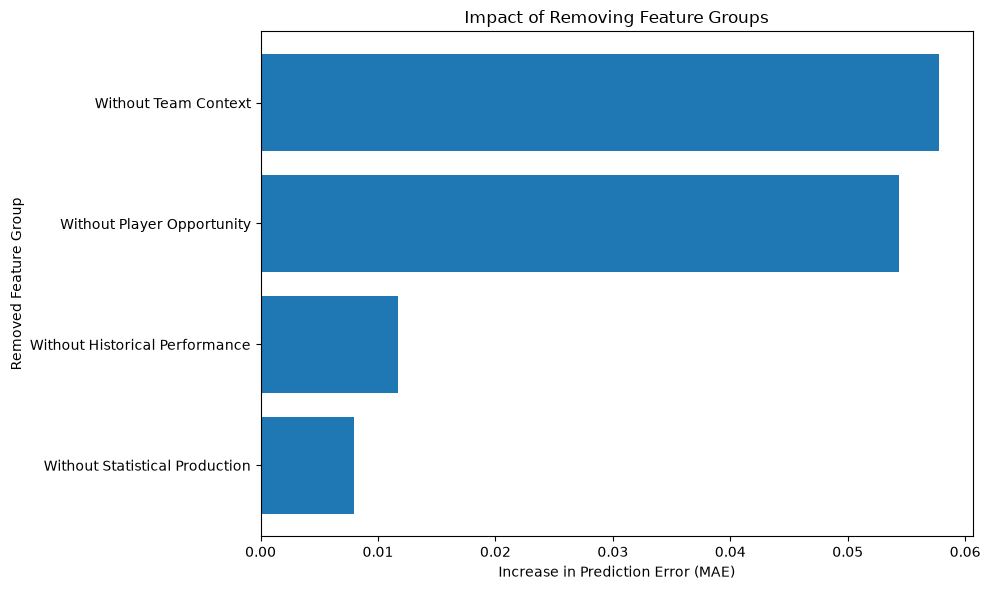

In [34]:

import matplotlib.pyplot as plt
import numpy as np

# -----------------------------------
# GRAPH 1: Overall model comparison
# -----------------------------------

model_names = model_results["Model"].to_list()
model_mae = model_results["MAE"].to_list()

plt.figure(figsize=(8, 5))
plt.bar(model_names, model_mae)

plt.title("Fantasy Football Prediction Model Comparison")
plt.xlabel("Prediction Model")
plt.ylabel("Mean Absolute Error (Lower is Better)")
plt.tight_layout()
plt.savefig("model_comparison.png", dpi=300)
plt.show()


# -----------------------------------
# GRAPH 2: Top 15 feature importance
# -----------------------------------

top_features = feature_importance.head(15).sort(
    "Importance"
)

plt.figure(figsize=(10, 7))
plt.barh(
    top_features["Feature"].to_list(),
    top_features["Importance"].to_list()
)

plt.title("Top 15 Most Influential Prediction Features")
plt.xlabel("Increase in MAE When Feature Is Shuffled")
plt.ylabel("Feature")
plt.tight_layout()
plt.savefig("feature_importance.png", dpi=300)
plt.show()


# -----------------------------------
# GRAPH 3: Prediction error by position
# -----------------------------------

position_chart = position_accuracy.sort("MAE")

plt.figure(figsize=(8, 5))
plt.bar(
    position_chart["Position"].to_list(),
    position_chart["MAE"].to_list()
)

plt.title("Fantasy Point Prediction Error by Position")
plt.xlabel("Player Position")
plt.ylabel("Mean Absolute Error")
plt.tight_layout()
plt.savefig("position_accuracy.png", dpi=300)
plt.show()


# -----------------------------------
# GRAPH 4: Feature group removal
# -----------------------------------

ablation_chart = ablation_comparison.filter(
    pl.col("Experiment") != "Full Model"
).sort("MAE_Increase")

plt.figure(figsize=(10, 6))
plt.barh(
    ablation_chart["Experiment"].to_list(),
    ablation_chart["MAE_Increase"].to_list()
)

plt.title("Impact of Removing Feature Groups")
plt.xlabel("Increase in Prediction Error (MAE)")
plt.ylabel("Removed Feature Group")
plt.tight_layout()
plt.savefig("feature_group_impact.png", dpi=300)
plt.show()



In [35]:

# Load weekly NFL team statistics
team_stats = nfl.load_team_stats(
    seasons=[2022, 2023, 2024, 2025],
    summary_level="week"
)

# Keep regular-season games only
team_stats = team_stats.filter(
    pl.col("season_type") == "REG"
)

print("Team statistics shape:", team_stats.shape)

# Show all available columns
print(team_stats.columns)

# Inspect a few rows
print(team_stats.head(5))


Team statistics shape: (2174, 138)
['season', 'week', 'team', 'season_type', 'game_id', 'opponent_team', 'completions', 'attempts', 'passing_yards', 'passing_tds', 'passing_interceptions', 'sacks_suffered', 'sack_yards_lost', 'sack_fumbles', 'sack_fumbles_lost', 'passing_air_yards', 'passing_yards_after_catch', 'passing_first_downs', 'passing_epa', 'passing_cpoe', 'passing_2pt_conversions', 'passing_10', 'passing_16', 'passing_20', 'passing_40', 'carries', 'rushing_yards', 'rushing_tds', 'rushing_fumbles', 'rushing_fumbles_lost', 'rushing_first_downs', 'rushing_epa', 'rushing_2pt_conversions', 'rushing_10', 'rushing_12', 'rushing_20', 'rushing_40', 'receptions', 'targets', 'receiving_yards', 'receiving_tds', 'receiving_fumbles', 'receiving_fumbles_lost', 'receiving_air_yards', 'receiving_yards_after_catch', 'receiving_first_downs', 'receiving_epa', 'receiving_2pt_conversions', 'receiving_10', 'receiving_16', 'receiving_20', 'receiving_40', 'special_teams_tds', 'def_tackles_solo', 'def_

In [36]:

# Create defensive statistics from the opposing offense's production

defensive_stats = team_stats.select([
    "season",
    "week",
    "game_id",
    pl.col("opponent_team").alias("defense_team"),

    pl.col("passing_yards").alias("passing_yards_allowed"),
    pl.col("passing_tds").alias("passing_tds_allowed"),
    pl.col("attempts").alias("passing_attempts_allowed"),
    pl.col("completions").alias("passing_completions_allowed"),

    pl.col("rushing_yards").alias("rushing_yards_allowed"),
    pl.col("rushing_tds").alias("rushing_tds_allowed"),

    pl.col("receiving_yards").alias("receiving_yards_allowed"),
    pl.col("receiving_tds").alias("receiving_tds_allowed"),
    pl.col("receptions").alias("receptions_allowed"),
    pl.col("targets").alias("targets_allowed")
])

# Sort each defense's games chronologically
defensive_stats = defensive_stats.sort([
    "defense_team",
    "season",
    "week"
])

print("Defensive dataset shape:", defensive_stats.shape)
print(defensive_stats.head(10))


Defensive dataset shape: (2174, 14)
shape: (10, 14)
┌────────┬──────┬─────────┬─────────┬─────────┬───┬─────────┬─────────┬─────────┬─────────┬────────┐
│ season ┆ week ┆ game_id ┆ defense ┆ passing ┆ … ┆ rushing ┆ receivi ┆ receivi ┆ recepti ┆ target │
│ ---    ┆ ---  ┆ ---     ┆ _team   ┆ _yards_ ┆   ┆ _tds_al ┆ ng_yard ┆ ng_tds_ ┆ ons_all ┆ s_allo │
│ i32    ┆ i32  ┆ str     ┆ ---     ┆ allowed ┆   ┆ lowed   ┆ s_allow ┆ allowed ┆ owed    ┆ wed    │
│        ┆      ┆         ┆ str     ┆ ---     ┆   ┆ ---     ┆ ed      ┆ ---     ┆ ---     ┆ ---    │
│        ┆      ┆         ┆         ┆ i32     ┆   ┆ i32     ┆ ---     ┆ i32     ┆ i32     ┆ i32    │
│        ┆      ┆         ┆         ┆         ┆   ┆         ┆ i32     ┆         ┆         ┆        │
╞════════╪══════╪═════════╪═════════╪═════════╪═══╪═════════╪═════════╪═════════╪═════════╪════════╡
│ 2022   ┆ 1    ┆ 2022_01 ┆ ARI     ┆ 360     ┆ … ┆ 1       ┆ 360     ┆ 5       ┆ 30      ┆ 39     │
│        ┆      ┆ _KC_ARI ┆         ┆  

In [37]:

defensive_variables = [
    "passing_yards_allowed",
    "passing_tds_allowed",
    "passing_attempts_allowed",
    "passing_completions_allowed",
    "rushing_yards_allowed",
    "rushing_tds_allowed",
    "receiving_yards_allowed",
    "receiving_tds_allowed",
    "receptions_allowed",
    "targets_allowed"
]

defensive_stats = defensive_stats.with_columns([
    pl.col(stat)
    .shift(1)
    .rolling_mean(window_size=3)
    .over(["defense_team", "season"])
    .alias(f"average_previous_3_{stat}")
    for stat in defensive_variables
])

print(
    defensive_stats.select([
        "season",
        "week",
        "defense_team",
        "average_previous_3_passing_yards_allowed",
        "average_previous_3_rushing_yards_allowed",
        "average_previous_3_receiving_yards_allowed"
    ]).filter(
        pl.col("defense_team") == "CAR"
    ).head(12)
)


shape: (12, 6)
┌────────┬──────┬──────────────┬──────────────────────┬──────────────────────┬─────────────────────┐
│ season ┆ week ┆ defense_team ┆ average_previous_3_p ┆ average_previous_3_r ┆ average_previous_3_ │
│ ---    ┆ ---  ┆ ---          ┆ assing_yar…          ┆ ushing_yar…          ┆ receiving_y…        │
│ i32    ┆ i32  ┆ str          ┆ ---                  ┆ ---                  ┆ ---                 │
│        ┆      ┆              ┆ f64                  ┆ f64                  ┆ f64                 │
╞════════╪══════╪══════════════╪══════════════════════╪══════════════════════╪═════════════════════╡
│ 2022   ┆ 1    ┆ CAR          ┆ null                 ┆ null                 ┆ null                │
│ 2022   ┆ 2    ┆ CAR          ┆ null                 ┆ null                 ┆ null                │
│ 2022   ┆ 3    ┆ CAR          ┆ null                 ┆ null                 ┆ null                │
│ 2022   ┆ 4    ┆ CAR          ┆ 225.333333           ┆ 134.666667          

In [38]:

# Calculate total fantasy points allowed by each defense
# against each individual position in each game.

fantasy_points_allowed = (
    fantasy_players
    .group_by([
        "season",
        "week",
        "opponent_team",
        "position"
    ])
    .agg(
        pl.col("fantasy_points_ppr").sum().alias("points_allowed")
    )
)

# Convert positions into separate columns
fantasy_points_allowed = fantasy_points_allowed.pivot(
    on="position",
    index=["season", "week", "opponent_team"],
    values="points_allowed",
    aggregate_function="sum"
)

# Rename the columns
fantasy_points_allowed = fantasy_points_allowed.rename({
    "opponent_team": "defense_team",
    "QB": "qb_points_allowed",
    "RB": "rb_points_allowed",
    "WR": "wr_points_allowed",
    "TE": "te_points_allowed"
})

# Add these statistics to the defensive dataset
defensive_stats = defensive_stats.join(
    fantasy_points_allowed,
    on=["season", "week", "defense_team"],
    how="left"
)

# Fill missing position totals with zero
position_point_columns = [
    "qb_points_allowed",
    "rb_points_allowed",
    "wr_points_allowed",
    "te_points_allowed"
]

defensive_stats = defensive_stats.with_columns([
    pl.col(col).fill_null(0)
    for col in position_point_columns
])

print(defensive_stats.select([
    "season",
    "week",
    "defense_team",
    "qb_points_allowed",
    "rb_points_allowed",
    "wr_points_allowed",
    "te_points_allowed"
]).head(10))


shape: (10, 7)
┌────────┬──────┬──────────────┬────────────────┬────────────────┬────────────────┬────────────────┐
│ season ┆ week ┆ defense_team ┆ qb_points_allo ┆ rb_points_allo ┆ wr_points_allo ┆ te_points_allo │
│ ---    ┆ ---  ┆ ---          ┆ wed            ┆ wed            ┆ wed            ┆ wed            │
│ i32    ┆ i32  ┆ str          ┆ ---            ┆ ---            ┆ ---            ┆ ---            │
│        ┆      ┆              ┆ f64            ┆ f64            ┆ f64            ┆ f64            │
╞════════╪══════╪══════════════╪════════════════╪════════════════╪════════════════╪════════════════╡
│ 2022   ┆ 1    ┆ ARI          ┆ 34.9           ┆ 42.5           ┆ 34.6           ┆ 35.2           │
│ 2022   ┆ 2    ┆ ARI          ┆ 18.98          ┆ 12.6           ┆ 31.7           ┆ 23.0           │
│ 2022   ┆ 3    ┆ ARI          ┆ 10.16          ┆ 11.8           ┆ 37.0           ┆ 13.9           │
│ 2022   ┆ 4    ┆ ARI          ┆ 5.88           ┆ 26.0           ┆ 17.7     

In [39]:

defensive_stats = defensive_stats.with_columns([
    pl.col(col)
    .shift(1)
    .rolling_mean(window_size=3)
    .over(["defense_team", "season"])
    .alias(f"average_previous_3_{col}")
    for col in position_point_columns
])

print(
    defensive_stats.select([
        "season",
        "week",
        "defense_team",
        "average_previous_3_qb_points_allowed",
        "average_previous_3_rb_points_allowed",
        "average_previous_3_wr_points_allowed",
        "average_previous_3_te_points_allowed"
    ])
    .filter(pl.col("defense_team") == "CAR")
    .head(12)
)


shape: (12, 7)
┌────────┬──────┬──────────────┬────────────────┬────────────────┬────────────────┬────────────────┐
│ season ┆ week ┆ defense_team ┆ average_previo ┆ average_previo ┆ average_previo ┆ average_previo │
│ ---    ┆ ---  ┆ ---          ┆ us_3_qb_points ┆ us_3_rb_points ┆ us_3_wr_points ┆ us_3_te_points │
│ i32    ┆ i32  ┆ str          ┆ _a…            ┆ _a…            ┆ _a…            ┆ _a…            │
│        ┆      ┆              ┆ ---            ┆ ---            ┆ ---            ┆ ---            │
│        ┆      ┆              ┆ f64            ┆ f64            ┆ f64            ┆ f64            │
╞════════╪══════╪══════════════╪════════════════╪════════════════╪════════════════╪════════════════╡
│ 2022   ┆ 1    ┆ CAR          ┆ null           ┆ null           ┆ null           ┆ null           │
│ 2022   ┆ 2    ┆ CAR          ┆ null           ┆ null           ┆ null           ┆ null           │
│ 2022   ┆ 3    ┆ CAR          ┆ null           ┆ null           ┆ null     

In [40]:

# Select the defensive features we want to add
defensive_feature_columns = [
    f"average_previous_3_{stat}"
    for stat in defensive_variables
] + [
    f"average_previous_3_{col}"
    for col in position_point_columns
]

# Keep the matchup identifiers and defensive features
defensive_features = defensive_stats.select(
    ["season", "week", "defense_team"] +
    defensive_feature_columns
)

# Attach defensive information to each player's upcoming matchup
fantasy_players = fantasy_players.join(
    defensive_features,
    left_on=["season", "week", "opponent_team"],
    right_on=["season", "week", "defense_team"],
    how="left"
)

print("Updated player dataset:", fantasy_players.shape)

# Inspect Christian McCaffrey's matchups
print(
    fantasy_players.filter(
        pl.col("player_display_name") == "Christian McCaffrey"
    ).select([
        "season",
        "week",
        "opponent_team",
        "fantasy_points_ppr",
        "average_previous_3_rushing_yards_allowed",
        "average_previous_3_rb_points_allowed"
    ]).head(15)
)


Updated player dataset: (23510, 180)
shape: (15, 6)
┌────────┬──────┬───────────────┬────────────────────┬──────────────────────┬──────────────────────┐
│ season ┆ week ┆ opponent_team ┆ fantasy_points_ppr ┆ average_previous_3_r ┆ average_previous_3_r │
│ ---    ┆ ---  ┆ ---           ┆ ---                ┆ ushing_yar…          ┆ b_points_a…          │
│ i32    ┆ i32  ┆ str           ┆ f64                ┆ ---                  ┆ ---                  │
│        ┆      ┆               ┆                    ┆ f64                  ┆ f64                  │
╞════════╪══════╪═══════════════╪════════════════════╪══════════════════════╪══════════════════════╡
│ 2022   ┆ 1    ┆ CLE           ┆ 15.7               ┆ null                 ┆ null                 │
│ 2022   ┆ 2    ┆ NYG           ┆ 16.8               ┆ null                 ┆ null                 │
│ 2022   ┆ 3    ┆ NO            ┆ 13.5               ┆ null                 ┆ null                 │
│ 2022   ┆ 4    ┆ ARI           ┆ 25.8 

In [44]:
[
    f"average_previous_3_{col}"
    for col in position_point_columns
]

new_feature_columns = feature_columns + defensive_feature_columns

model_data_with_defense = (
    fantasy_players
    .select(
        new_feature_columns +
        ["position", "season", "fantasy_points_ppr"]
    )
    .drop_nulls()
)

print("New modeling dataset:", model_data_with_defense.shape)

New modeling dataset: (16885, 32)


In [45]:
# Create original dataset using the same player-week observations
model_data_without_defense = model_data_with_defense.select(
    feature_columns +
    ["position", "season", "fantasy_points_ppr"]
)

# Convert position into numerical columns
model_data_with_defense = model_data_with_defense.to_dummies(
    columns=["position"]
)

model_data_without_defense = model_data_without_defense.to_dummies(
    columns=["position"]
)

# Split into training data (2022-2024) and testing data (2025)
train_with_defense = model_data_with_defense.filter(
    pl.col("season") < 2025
)

test_with_defense = model_data_with_defense.filter(
    pl.col("season") == 2025
)

train_without_defense = model_data_without_defense.filter(
    pl.col("season") < 2025
)

test_without_defense = model_data_without_defense.filter(
    pl.col("season") == 2025
)

print("Training observations:", train_with_defense.height)
print("Testing observations:", test_with_defense.height)

print(
    "Matching test observations:",
    test_with_defense.height == test_without_defense.height
)

Training observations: 12560
Testing observations: 4325
Matching test observations: True


In [46]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import polars as pl

# Separate features and target for each dataset
def get_model_data(train_data, test_data):
    feature_names = [
        col for col in train_data.columns
        if col not in ["season", "fantasy_points_ppr"]
    ]

    X_train = train_data.select(feature_names).to_numpy()
    y_train = train_data["fantasy_points_ppr"].to_numpy()

    X_test = test_data.select(feature_names).to_numpy()
    y_test = test_data["fantasy_points_ppr"].to_numpy()

    return X_train, y_train, X_test, y_test


# Prepare datasets
X_train_base, y_train_base, X_test_base, y_test_base = get_model_data(
    train_without_defense,
    test_without_defense
)

X_train_def, y_train_def, X_test_def, y_test_def = get_model_data(
    train_with_defense,
    test_with_defense
)


# Function to evaluate a model
def evaluate_model(model, X_train, y_train, X_test, y_test):
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)

    return {
        "MAE": mean_absolute_error(y_test, predictions),
        "RMSE": np.sqrt(mean_squared_error(y_test, predictions)),
        "R2": r2_score(y_test, predictions)
    }


# Train baseline models
baseline_base = DummyRegressor(strategy="mean")
baseline_def = DummyRegressor(strategy="mean")

# Train linear regression models
linear_base = LinearRegression()
linear_def = LinearRegression()

# Train random forest models
rf_base = RandomForestRegressor(
    n_estimators=300,
    max_depth=15,
    min_samples_leaf=5,
    random_state=42,
    n_jobs=-1
)

rf_def = RandomForestRegressor(
    n_estimators=300,
    max_depth=15,
    min_samples_leaf=5,
    random_state=42,
    n_jobs=-1
)


# Evaluate all six models
results = []

models = [
    ("Baseline - No Defense", baseline_base, X_train_base, y_train_base, X_test_base, y_test_base),
    ("Baseline - With Defense", baseline_def, X_train_def, y_train_def, X_test_def, y_test_def),
    ("Linear - No Defense", linear_base, X_train_base, y_train_base, X_test_base, y_test_base),
    ("Linear - With Defense", linear_def, X_train_def, y_train_def, X_test_def, y_test_def),
    ("Random Forest - No Defense", rf_base, X_train_base, y_train_base, X_test_base, y_test_base),
    ("Random Forest - With Defense", rf_def, X_train_def, y_train_def, X_test_def, y_test_def)
]

for name, model, X_train, y_train, X_test, y_test in models:
    scores = evaluate_model(model, X_train, y_train, X_test, y_test)

    results.append({
        "Model": name,
        **scores
    })


# Display comparison
comparison_results = pl.DataFrame(results)

print(comparison_results)

shape: (6, 4)
┌──────────────────────────────┬──────────┬──────────┬──────────┐
│ Model                        ┆ MAE      ┆ RMSE     ┆ R2       │
│ ---                          ┆ ---      ┆ ---      ┆ ---      │
│ str                          ┆ f64      ┆ f64      ┆ f64      │
╞══════════════════════════════╪══════════╪══════════╪══════════╡
│ Baseline - No Defense        ┆ 6.494839 ┆ 8.128325 ┆ -0.00139 │
│ Baseline - With Defense      ┆ 6.494839 ┆ 8.128325 ┆ -0.00139 │
│ Linear - No Defense          ┆ 4.664279 ┆ 6.40449  ┆ 0.378316 │
│ Linear - With Defense        ┆ 4.646375 ┆ 6.399466 ┆ 0.379291 │
│ Random Forest - No Defense   ┆ 4.728599 ┆ 6.481098 ┆ 0.363354 │
│ Random Forest - With Defense ┆ 4.704514 ┆ 6.4449   ┆ 0.370446 │
└──────────────────────────────┴──────────┴──────────┴──────────┘


In [47]:
from sklearn.inspection import permutation_importance

# Get feature names from the new model
feature_names_def = [
    col for col in train_with_defense.columns
    if col not in ["season", "fantasy_points_ppr"]
]

# Calculate permutation importance
defense_importance = permutation_importance(
    rf_def,
    X_test_def,
    y_test_def,
    n_repeats=10,
    random_state=42,
    scoring="neg_mean_absolute_error",
    n_jobs=-1
)

# Create importance table
importance_df = pl.DataFrame({
    "Feature": feature_names_def,
    "Importance": defense_importance.importances_mean,
    "Std": defense_importance.importances_std
}).sort(
    "Importance",
    descending=True
)

# Display the 20 most important features
print("TOP 20 MOST IMPORTANT FEATURES")
print(importance_df.head(20))

# Display defensive features only
defensive_importance_df = importance_df.filter(
    pl.col("Feature").str.starts_with("average_previous_3_")
    & ~pl.col("Feature").is_in([
        "average_previous_3_games",
        "average_previous_3_targets",
        "average_previous_3_carries"
    ])
)

print("\nDEFENSIVE FEATURE IMPORTANCE")
print(defensive_importance_df)

TOP 20 MOST IMPORTANT FEATURES
shape: (20, 3)
┌─────────────────────────────────┬────────────┬──────────┐
│ Feature                         ┆ Importance ┆ Std      │
│ ---                             ┆ ---        ┆ ---      │
│ str                             ┆ f64        ┆ f64      │
╞═════════════════════════════════╪════════════╪══════════╡
│ average_previous_3_games        ┆ 1.460626   ┆ 0.049993 │
│ average_previous_3_targets      ┆ 0.3028     ┆ 0.018682 │
│ average_previous_3_rushing_yar… ┆ 0.073012   ┆ 0.005903 │
│ average_previous_3_attempts     ┆ 0.060371   ┆ 0.005627 │
│ previous_week_fantasy_points    ┆ 0.052926   ┆ 0.007835 │
│ average_previous_3_passing_yar… ┆ 0.050656   ┆ 0.005946 │
│ average_previous_3_carries      ┆ 0.050371   ┆ 0.007111 │
│ average_previous_3_receiving_y… ┆ 0.029635   ┆ 0.003047 │
│ average_previous_3_completions  ┆ 0.028027   ┆ 0.004692 │
│ average_previous_3_passing_yar… ┆ 0.01657    ┆ 0.002198 │
│ average_previous_3_receiving_y… ┆ 0.014672   ┆ 0.001

In [48]:
# Keep ONLY the actual defensive features
defensive_importance_df = importance_df.filter(
    pl.col("Feature").is_in(defensive_feature_columns)
)

print("CORRECTED DEFENSIVE FEATURE IMPORTANCE")
print(defensive_importance_df)

CORRECTED DEFENSIVE FEATURE IMPORTANCE
shape: (14, 3)
┌─────────────────────────────────┬────────────┬──────────┐
│ Feature                         ┆ Importance ┆ Std      │
│ ---                             ┆ ---        ┆ ---      │
│ str                             ┆ f64        ┆ f64      │
╞═════════════════════════════════╪════════════╪══════════╡
│ average_previous_3_passing_yar… ┆ 0.01657    ┆ 0.002198 │
│ average_previous_3_receiving_y… ┆ 0.014672   ┆ 0.001762 │
│ average_previous_3_qb_points_a… ┆ 0.012044   ┆ 0.003027 │
│ average_previous_3_rushing_yar… ┆ 0.011071   ┆ 0.004171 │
│ average_previous_3_wr_points_a… ┆ 0.009987   ┆ 0.003696 │
│ average_previous_3_passing_att… ┆ 0.00853    ┆ 0.002044 │
│ average_previous_3_rb_points_a… ┆ 0.007368   ┆ 0.003268 │
│ average_previous_3_targets_all… ┆ 0.007077   ┆ 0.002572 │
│ average_previous_3_receptions_… ┆ 0.004525   ┆ 0.0017   │
│ average_previous_3_passing_com… ┆ 0.004232   ┆ 0.00164  │
│ average_previous_3_rushing_tds… ┆ 0.004092  

In [49]:
# Define the feature groups

feature_groups = {
    "Historical Player Performance": [
        "previous_week_fantasy_points",
        "average_previous_3_games"
    ],

    "Player Opportunity": [
        "average_previous_3_targets",
        "average_previous_3_carries",
        "average_previous_3_attempts",
        "average_previous_3_completions"
    ],

    "Player Statistical Production": [
        "average_previous_3_receptions",
        "average_previous_3_receiving_yards",
        "average_previous_3_rushing_yards",
        "average_previous_3_passing_yards",
        "average_previous_3_passing_tds",
        "average_previous_3_receiving_tds",
        "average_previous_3_rushing_tds",
        "average_previous_3_passing_interceptions"
    ],

    "Opponent Defensive Performance": defensive_feature_columns,

    "Player Position and Game Context": [
        "week",
        "position_QB",
        "position_RB",
        "position_WR",
        "position_TE"
    ]
}

# Keep only features that actually exist in our dataset
feature_groups = {
    group: [col for col in columns if col in feature_names_def]
    for group, columns in feature_groups.items()
}

# Evaluate the full model
full_model = RandomForestRegressor(
    n_estimators=300,
    max_depth=15,
    min_samples_leaf=5,
    random_state=42,
    n_jobs=-1
)

full_scores = evaluate_model(
    full_model,
    X_train_def,
    y_train_def,
    X_test_def,
    y_test_def
)

full_mae = full_scores["MAE"]

ablation_results = [{
    "Experiment": "Full Model",
    "MAE": full_scores["MAE"],
    "RMSE": full_scores["RMSE"],
    "R2": full_scores["R2"],
    "MAE Increase": 0.0
}]

# Remove one feature group at a time
for group, columns_to_remove in feature_groups.items():

    remaining_features = [
        col for col in feature_names_def
        if col not in columns_to_remove
    ]

    X_train_reduced = train_with_defense.select(
        remaining_features
    ).to_numpy()

    X_test_reduced = test_with_defense.select(
        remaining_features
    ).to_numpy()

    model = RandomForestRegressor(
        n_estimators=300,
        max_depth=15,
        min_samples_leaf=5,
        random_state=42,
        n_jobs=-1
    )

    scores = evaluate_model(
        model,
        X_train_reduced,
        y_train_def,
        X_test_reduced,
        y_test_def
    )

    ablation_results.append({
        "Experiment": f"Without {group}",
        "MAE": scores["MAE"],
        "RMSE": scores["RMSE"],
        "R2": scores["R2"],
        "MAE Increase": scores["MAE"] - full_mae
    })

# Display results
ablation_df = pl.DataFrame(ablation_results).sort(
    "MAE",
    descending=True
)

print("FEATURE GROUP ABLATION RESULTS")
print(ablation_df)

FEATURE GROUP ABLATION RESULTS
shape: (6, 5)
┌─────────────────────────────────┬──────────┬──────────┬──────────┬──────────────┐
│ Experiment                      ┆ MAE      ┆ RMSE     ┆ R2       ┆ MAE Increase │
│ ---                             ┆ ---      ┆ ---      ┆ ---      ┆ ---          │
│ str                             ┆ f64      ┆ f64      ┆ f64      ┆ f64          │
╞═════════════════════════════════╪══════════╪══════════╪══════════╪══════════════╡
│ Without Player Opportunity      ┆ 4.759043 ┆ 6.473373 ┆ 0.364871 ┆ 0.054528     │
│ Without Opponent Defensive Per… ┆ 4.728599 ┆ 6.481098 ┆ 0.363354 ┆ 0.024085     │
│ Without Player Statistical Pro… ┆ 4.721049 ┆ 6.465421 ┆ 0.36643  ┆ 0.016535     │
│ Without Historical Player Perf… ┆ 4.71023  ┆ 6.438969 ┆ 0.371604 ┆ 0.005716     │
│ Without Player Position and Ga… ┆ 4.70527  ┆ 6.44696  ┆ 0.370043 ┆ 0.000756     │
│ Full Model                      ┆ 4.704514 ┆ 6.4449   ┆ 0.370446 ┆ 0.0          │
└──────────────────────────────

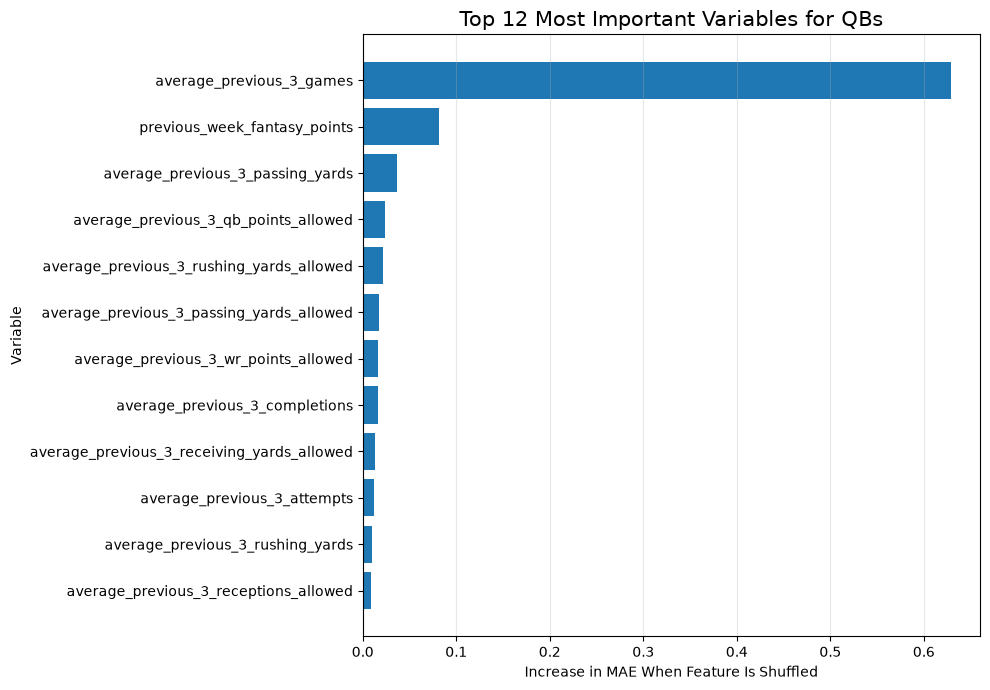


TOP VARIABLES FOR QBs
shape: (12, 3)
┌─────────────────────────────────┬────────────┬──────────┐
│ Feature                         ┆ Importance ┆ Std      │
│ ---                             ┆ ---        ┆ ---      │
│ str                             ┆ f64        ┆ f64      │
╞═════════════════════════════════╪════════════╪══════════╡
│ average_previous_3_games        ┆ 0.628624   ┆ 0.157326 │
│ previous_week_fantasy_points    ┆ 0.081339   ┆ 0.036354 │
│ average_previous_3_passing_yar… ┆ 0.036524   ┆ 0.012498 │
│ average_previous_3_qb_points_a… ┆ 0.024034   ┆ 0.014461 │
│ average_previous_3_rushing_yar… ┆ 0.021528   ┆ 0.016379 │
│ average_previous_3_passing_yar… ┆ 0.017166   ┆ 0.005969 │
│ average_previous_3_wr_points_a… ┆ 0.016595   ┆ 0.008796 │
│ average_previous_3_completions  ┆ 0.016108   ┆ 0.010699 │
│ average_previous_3_receiving_y… ┆ 0.013342   ┆ 0.004102 │
│ average_previous_3_attempts     ┆ 0.012123   ┆ 0.015903 │
│ average_previous_3_rushing_yar… ┆ 0.009891   ┆ 0.019979 │
│ 

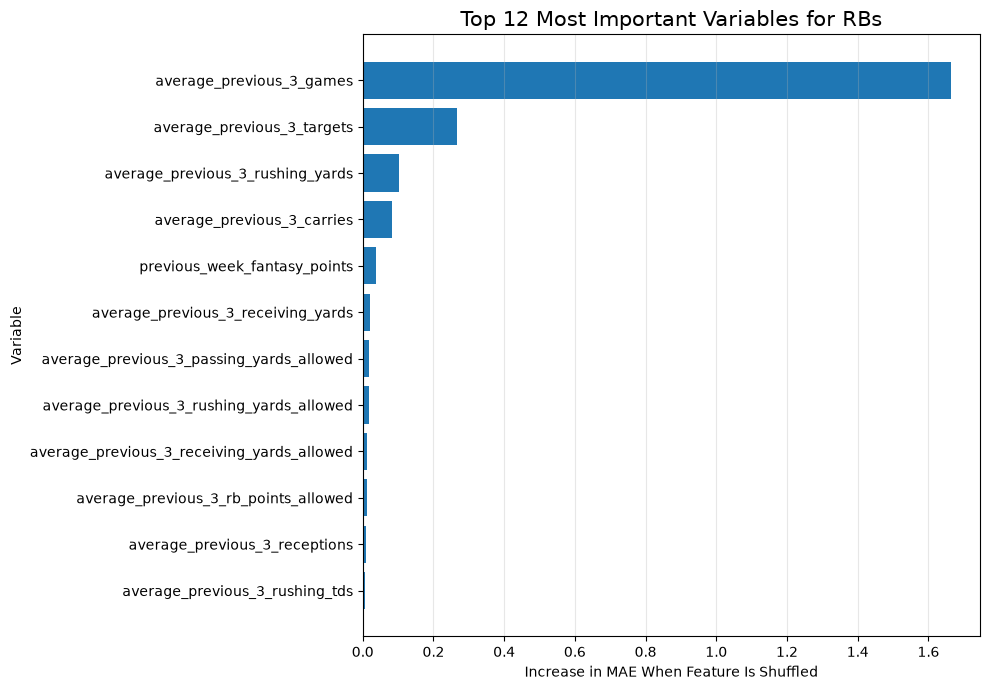


TOP VARIABLES FOR RBs
shape: (12, 3)
┌─────────────────────────────────┬────────────┬──────────┐
│ Feature                         ┆ Importance ┆ Std      │
│ ---                             ┆ ---        ┆ ---      │
│ str                             ┆ f64        ┆ f64      │
╞═════════════════════════════════╪════════════╪══════════╡
│ average_previous_3_games        ┆ 1.662764   ┆ 0.113749 │
│ average_previous_3_targets      ┆ 0.266602   ┆ 0.021159 │
│ average_previous_3_rushing_yar… ┆ 0.103839   ┆ 0.026075 │
│ average_previous_3_carries      ┆ 0.081533   ┆ 0.016161 │
│ previous_week_fantasy_points    ┆ 0.038817   ┆ 0.014629 │
│ average_previous_3_receiving_y… ┆ 0.020587   ┆ 0.006027 │
│ average_previous_3_passing_yar… ┆ 0.018474   ┆ 0.003713 │
│ average_previous_3_rushing_yar… ┆ 0.017607   ┆ 0.006861 │
│ average_previous_3_receiving_y… ┆ 0.0123     ┆ 0.003324 │
│ average_previous_3_rb_points_a… ┆ 0.01117    ┆ 0.007314 │
│ average_previous_3_receptions   ┆ 0.008947   ┆ 0.005334 │
│ 

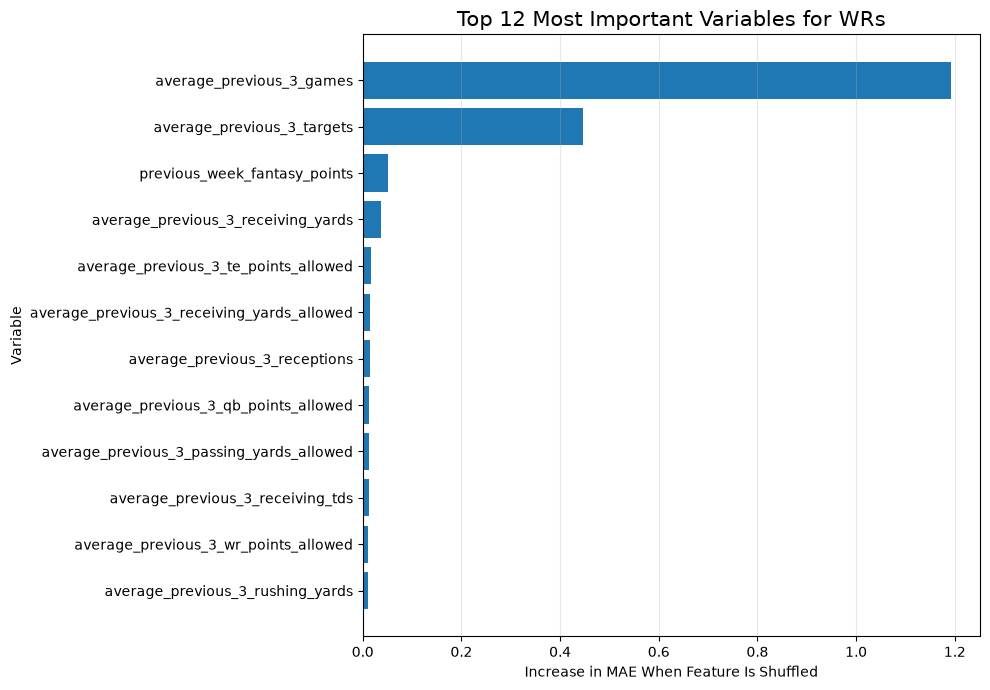


TOP VARIABLES FOR WRs
shape: (12, 3)
┌─────────────────────────────────┬────────────┬──────────┐
│ Feature                         ┆ Importance ┆ Std      │
│ ---                             ┆ ---        ┆ ---      │
│ str                             ┆ f64        ┆ f64      │
╞═════════════════════════════════╪════════════╪══════════╡
│ average_previous_3_games        ┆ 1.191528   ┆ 0.070398 │
│ average_previous_3_targets      ┆ 0.446602   ┆ 0.036286 │
│ previous_week_fantasy_points    ┆ 0.050835   ┆ 0.011396 │
│ average_previous_3_receiving_y… ┆ 0.037729   ┆ 0.008606 │
│ average_previous_3_te_points_a… ┆ 0.016756   ┆ 0.006667 │
│ average_previous_3_receiving_y… ┆ 0.01564    ┆ 0.003623 │
│ average_previous_3_receptions   ┆ 0.01395    ┆ 0.005207 │
│ average_previous_3_qb_points_a… ┆ 0.012854   ┆ 0.006453 │
│ average_previous_3_passing_yar… ┆ 0.012231   ┆ 0.003776 │
│ average_previous_3_receiving_t… ┆ 0.011992   ┆ 0.002793 │
│ average_previous_3_wr_points_a… ┆ 0.010989   ┆ 0.006006 │
│ 

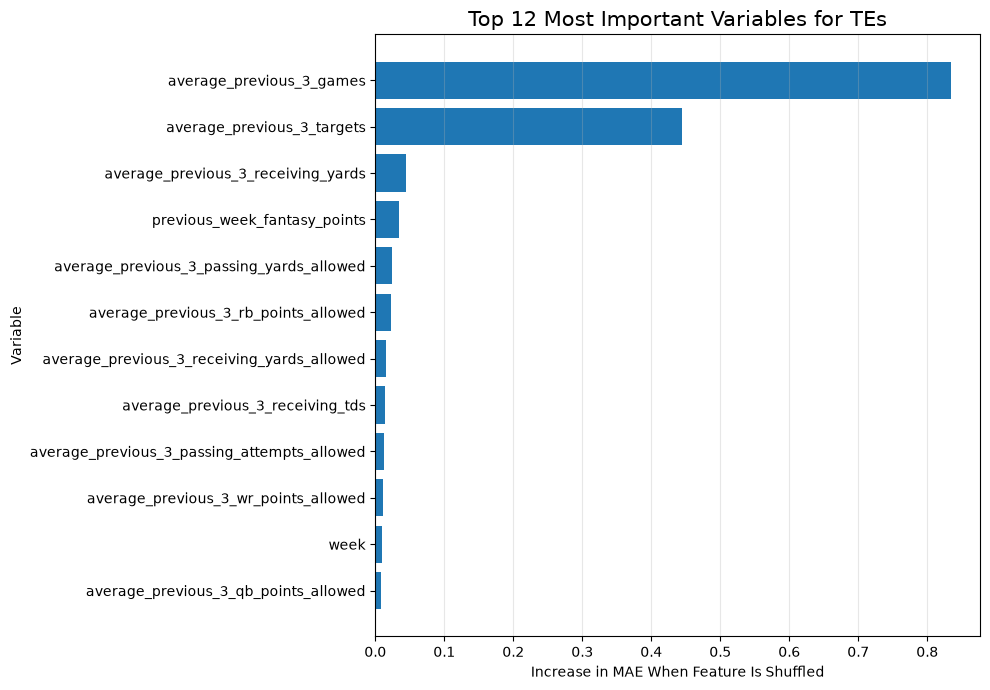


TOP VARIABLES FOR TEs
shape: (12, 3)
┌─────────────────────────────────┬────────────┬──────────┐
│ Feature                         ┆ Importance ┆ Std      │
│ ---                             ┆ ---        ┆ ---      │
│ str                             ┆ f64        ┆ f64      │
╞═════════════════════════════════╪════════════╪══════════╡
│ average_previous_3_games        ┆ 0.834682   ┆ 0.051893 │
│ average_previous_3_targets      ┆ 0.444199   ┆ 0.036055 │
│ average_previous_3_receiving_y… ┆ 0.0445     ┆ 0.01066  │
│ previous_week_fantasy_points    ┆ 0.033878   ┆ 0.013223 │
│ average_previous_3_passing_yar… ┆ 0.024433   ┆ 0.007295 │
│ average_previous_3_rb_points_a… ┆ 0.022574   ┆ 0.006054 │
│ average_previous_3_receiving_y… ┆ 0.016031   ┆ 0.006302 │
│ average_previous_3_receiving_t… ┆ 0.013644   ┆ 0.00272  │
│ average_previous_3_passing_att… ┆ 0.011942   ┆ 0.004655 │
│ average_previous_3_wr_points_a… ┆ 0.010967   ┆ 0.005919 │
│ week                            ┆ 0.010333   ┆ 0.007455 │
│ 

In [50]:

import matplotlib.pyplot as plt
import polars as pl
from sklearn.inspection import permutation_importance

# Positions to analyze
positions = ["QB", "RB", "WR", "TE"]

# Store importance results for each position
position_importance_results = {}

for position in positions:

    # Identify observations belonging to this position
    position_mask = (
        test_with_defense[f"position_{position}"]
        .to_numpy()
        .astype(bool)
    )

    # Select only this position's observations
    X_position = X_test_def[position_mask]
    y_position = y_test_def[position_mask]

    # Calculate permutation importance
    importance = permutation_importance(
        rf_def,
        X_position,
        y_position,
        n_repeats=10,
        random_state=42,
        scoring="neg_mean_absolute_error",
        n_jobs=-1
    )

    # Create importance table
    importance_df_position = pl.DataFrame({
        "Feature": feature_names_def,
        "Importance": importance.importances_mean,
        "Std": importance.importances_std
    }).sort(
        "Importance",
        descending=True
    )

    position_importance_results[position] = importance_df_position

    # Select the top 12 variables
    top_features = importance_df_position.head(12).sort(
        "Importance"
    )

    # Convert to Python lists for plotting
    feature_labels = top_features["Feature"].to_list()
    importance_values = top_features["Importance"].to_list()

    # Create graph
    plt.figure(figsize=(10, 7))

    plt.barh(
        feature_labels,
        importance_values
    )

    plt.xlabel("Increase in MAE When Feature Is Shuffled")
    plt.ylabel("Variable")

    plt.title(
        f"Top 12 Most Important Variables for {position}s",
        fontsize=15
    )

    plt.grid(axis="x", alpha=0.3)
    plt.tight_layout()

    # Save high-resolution graph
    filename = f"{position.lower()}_feature_importance.png"

    plt.savefig(
        filename,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

    print(f"\nTOP VARIABLES FOR {position}s")
    print(importance_df_position.head(12))


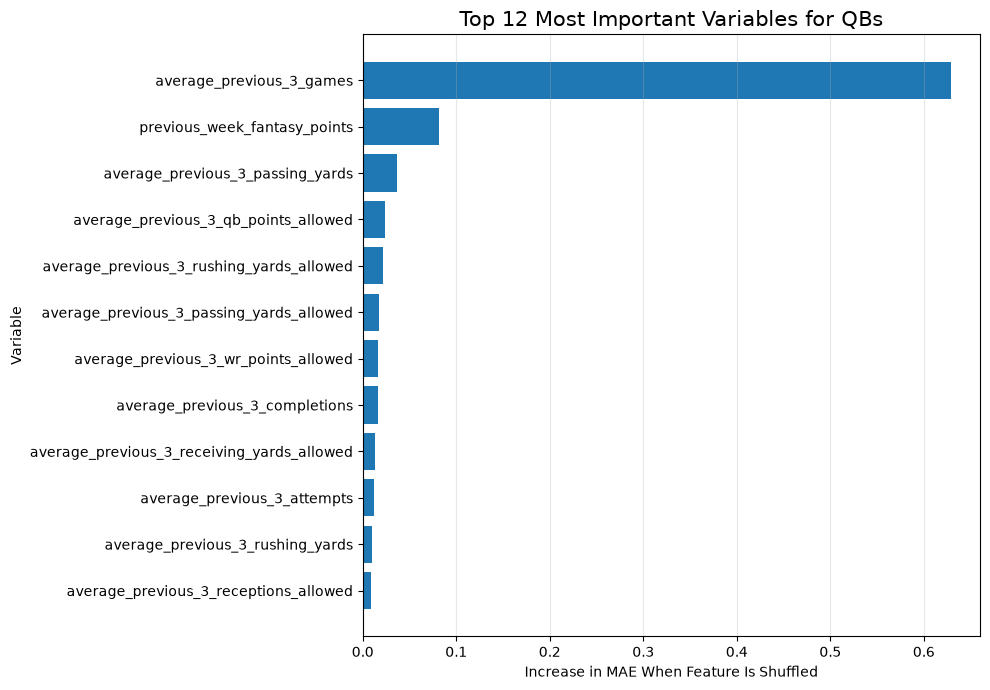


TOP VARIABLES FOR QBs
shape: (12, 3)
┌─────────────────────────────────┬────────────┬──────────┐
│ Feature                         ┆ Importance ┆ Std      │
│ ---                             ┆ ---        ┆ ---      │
│ str                             ┆ f64        ┆ f64      │
╞═════════════════════════════════╪════════════╪══════════╡
│ average_previous_3_games        ┆ 0.628624   ┆ 0.157326 │
│ previous_week_fantasy_points    ┆ 0.081339   ┆ 0.036354 │
│ average_previous_3_passing_yar… ┆ 0.036524   ┆ 0.012498 │
│ average_previous_3_qb_points_a… ┆ 0.024034   ┆ 0.014461 │
│ average_previous_3_rushing_yar… ┆ 0.021528   ┆ 0.016379 │
│ average_previous_3_passing_yar… ┆ 0.017166   ┆ 0.005969 │
│ average_previous_3_wr_points_a… ┆ 0.016595   ┆ 0.008796 │
│ average_previous_3_completions  ┆ 0.016108   ┆ 0.010699 │
│ average_previous_3_receiving_y… ┆ 0.013342   ┆ 0.004102 │
│ average_previous_3_attempts     ┆ 0.012123   ┆ 0.015903 │
│ average_previous_3_rushing_yar… ┆ 0.009891   ┆ 0.019979 │
│ 

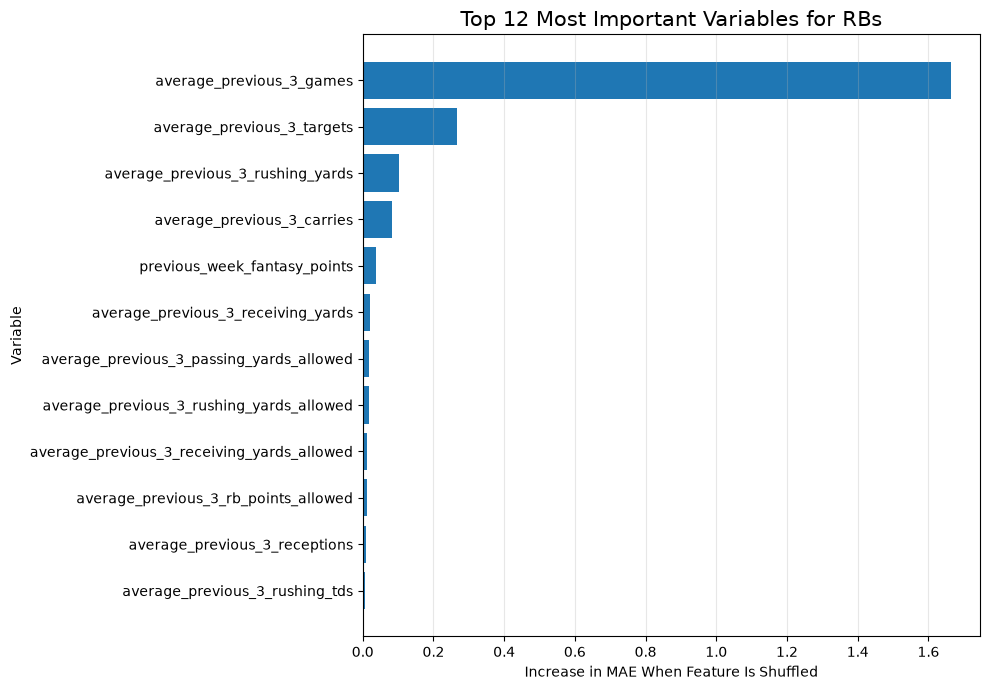


TOP VARIABLES FOR RBs
shape: (12, 3)
┌─────────────────────────────────┬────────────┬──────────┐
│ Feature                         ┆ Importance ┆ Std      │
│ ---                             ┆ ---        ┆ ---      │
│ str                             ┆ f64        ┆ f64      │
╞═════════════════════════════════╪════════════╪══════════╡
│ average_previous_3_games        ┆ 1.662764   ┆ 0.113749 │
│ average_previous_3_targets      ┆ 0.266602   ┆ 0.021159 │
│ average_previous_3_rushing_yar… ┆ 0.103839   ┆ 0.026075 │
│ average_previous_3_carries      ┆ 0.081533   ┆ 0.016161 │
│ previous_week_fantasy_points    ┆ 0.038817   ┆ 0.014629 │
│ average_previous_3_receiving_y… ┆ 0.020587   ┆ 0.006027 │
│ average_previous_3_passing_yar… ┆ 0.018474   ┆ 0.003713 │
│ average_previous_3_rushing_yar… ┆ 0.017607   ┆ 0.006861 │
│ average_previous_3_receiving_y… ┆ 0.0123     ┆ 0.003324 │
│ average_previous_3_rb_points_a… ┆ 0.01117    ┆ 0.007314 │
│ average_previous_3_receptions   ┆ 0.008947   ┆ 0.005334 │
│ 

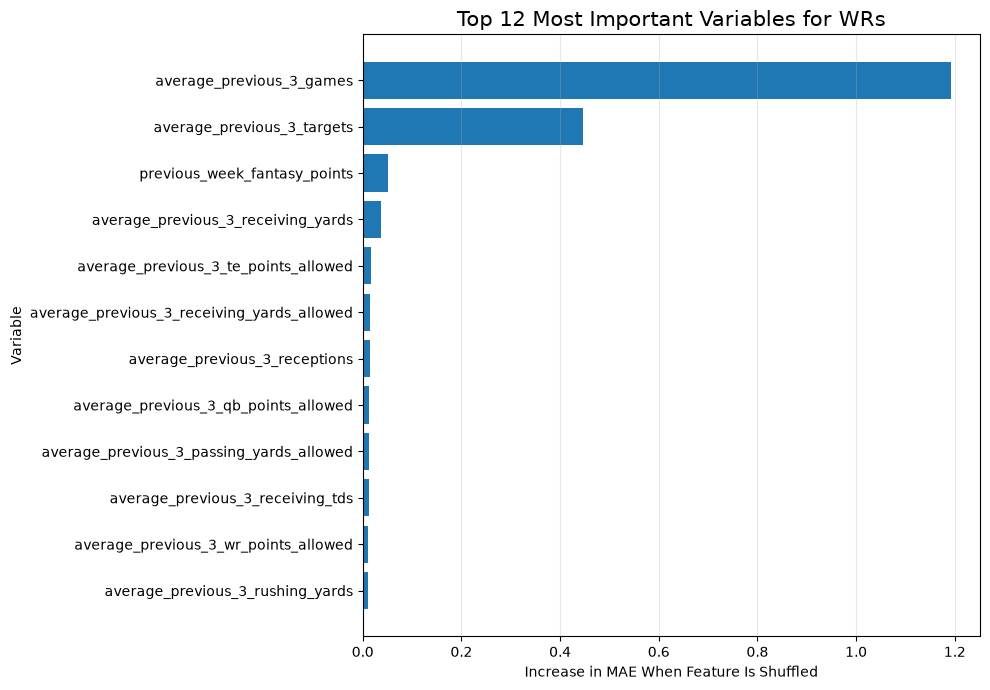


TOP VARIABLES FOR WRs
shape: (12, 3)
┌─────────────────────────────────┬────────────┬──────────┐
│ Feature                         ┆ Importance ┆ Std      │
│ ---                             ┆ ---        ┆ ---      │
│ str                             ┆ f64        ┆ f64      │
╞═════════════════════════════════╪════════════╪══════════╡
│ average_previous_3_games        ┆ 1.191528   ┆ 0.070398 │
│ average_previous_3_targets      ┆ 0.446602   ┆ 0.036286 │
│ previous_week_fantasy_points    ┆ 0.050835   ┆ 0.011396 │
│ average_previous_3_receiving_y… ┆ 0.037729   ┆ 0.008606 │
│ average_previous_3_te_points_a… ┆ 0.016756   ┆ 0.006667 │
│ average_previous_3_receiving_y… ┆ 0.01564    ┆ 0.003623 │
│ average_previous_3_receptions   ┆ 0.01395    ┆ 0.005207 │
│ average_previous_3_qb_points_a… ┆ 0.012854   ┆ 0.006453 │
│ average_previous_3_passing_yar… ┆ 0.012231   ┆ 0.003776 │
│ average_previous_3_receiving_t… ┆ 0.011992   ┆ 0.002793 │
│ average_previous_3_wr_points_a… ┆ 0.010989   ┆ 0.006006 │
│ 

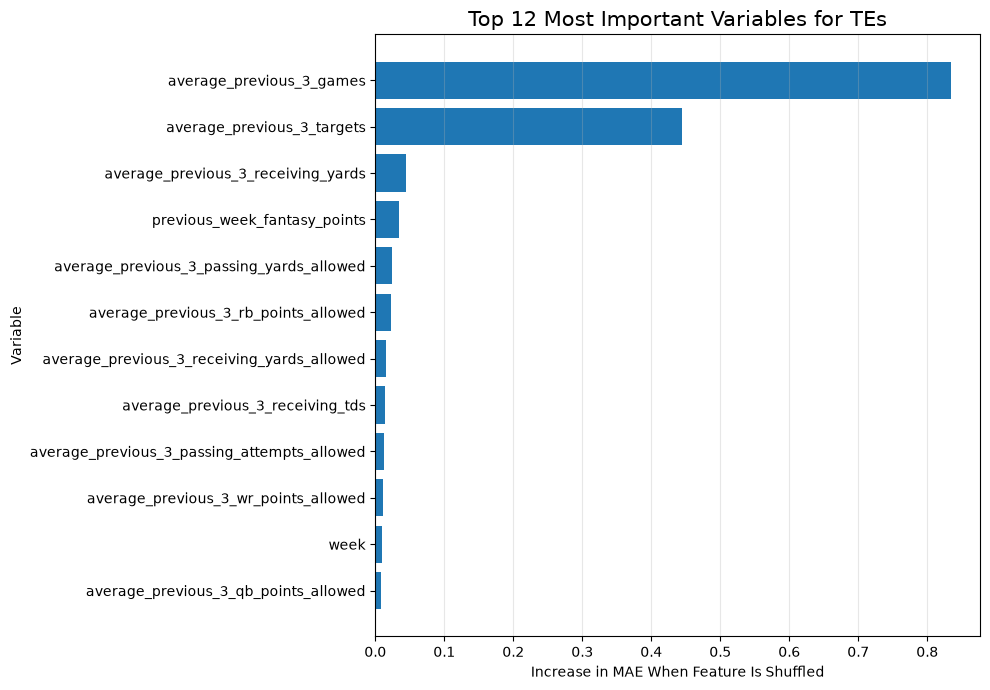


TOP VARIABLES FOR TEs
shape: (12, 3)
┌─────────────────────────────────┬────────────┬──────────┐
│ Feature                         ┆ Importance ┆ Std      │
│ ---                             ┆ ---        ┆ ---      │
│ str                             ┆ f64        ┆ f64      │
╞═════════════════════════════════╪════════════╪══════════╡
│ average_previous_3_games        ┆ 0.834682   ┆ 0.051893 │
│ average_previous_3_targets      ┆ 0.444199   ┆ 0.036055 │
│ average_previous_3_receiving_y… ┆ 0.0445     ┆ 0.01066  │
│ previous_week_fantasy_points    ┆ 0.033878   ┆ 0.013223 │
│ average_previous_3_passing_yar… ┆ 0.024433   ┆ 0.007295 │
│ average_previous_3_rb_points_a… ┆ 0.022574   ┆ 0.006054 │
│ average_previous_3_receiving_y… ┆ 0.016031   ┆ 0.006302 │
│ average_previous_3_receiving_t… ┆ 0.013644   ┆ 0.00272  │
│ average_previous_3_passing_att… ┆ 0.011942   ┆ 0.004655 │
│ average_previous_3_wr_points_a… ┆ 0.010967   ┆ 0.005919 │
│ week                            ┆ 0.010333   ┆ 0.007455 │
│ 

In [53]:
import matplotlib.pyplot as plt
import polars as pl
from sklearn.inspection import permutation_importance

def format_feature_name(feature):
    feature = feature.replace("average_previous_3_", "")

    if feature.endswith("_allowed"):
        feature = feature.replace("_allowed", "")
        feature = "Opposing " + feature.replace("_", " ").title()
    else:
        feature = feature.replace("_", " ").title()

    return feature

positions = ["QB", "RB", "WR", "TE"]
position_importance_results = {}

for position in positions:
    position_mask = (
        test_with_defense[f"position_{position}"]
        .to_numpy()
        .astype(bool)
    )

    X_position = X_test_def[position_mask]
    y_position = y_test_def[position_mask]

    importance = permutation_importance(
        rf_def,
        X_position,
        y_position,
        n_repeats=10,
        random_state=42,
        scoring="neg_mean_absolute_error",
        n_jobs=-1
    )

    importance_df_position = pl.DataFrame({
        "Feature": feature_names_def,
        "Importance": importance.importances_mean,
        "Std": importance.importances_std
    }).sort("Importance", descending=True)

    position_importance_results[position] = importance_df_position

    top_features = importance_df_position.head(12).sort("Importance")

    feature_labels = [
    format_feature_name(feature)
    for feature in top_features["Feature"].to_list()
]
    importance_values = top_features["Importance"].to_list()

    plt.figure(figsize=(10, 7))
    plt.barh(feature_labels, importance_values)

    plt.xlabel("Increase in MAE When Feature Is Shuffled")
    plt.ylabel("Variable")
    plt.title(f"Top 12 Most Important Variables for {position}s", fontsize=15)

    plt.grid(axis="x", alpha=0.3)
    plt.tight_layout()

    filename = f"{position.lower()}_feature_importance.png"
    plt.savefig(filename, dpi=300, bbox_inches="tight")
    plt.show()

    print(f"\nTOP VARIABLES FOR {position}s")
    print(importance_df_position.head(12))

In [52]:
position_importance_results["QB"]

Feature,Importance,Std
str,f64,f64
"""average_previous_3_games""",0.628624,0.157326
"""previous_week_fantasy_points""",0.081339,0.036354
"""average_previous_3_passing_yar…",0.036524,0.012498
"""average_previous_3_qb_points_a…",0.024034,0.014461
"""average_previous_3_rushing_yar…",0.021528,0.016379
"""average_previous_3_passing_yar…",0.017166,0.005969
"""average_previous_3_wr_points_a…",0.016595,0.008796
"""average_previous_3_completions""",0.016108,0.010699
"""average_previous_3_receiving_y…",0.013342,0.004102


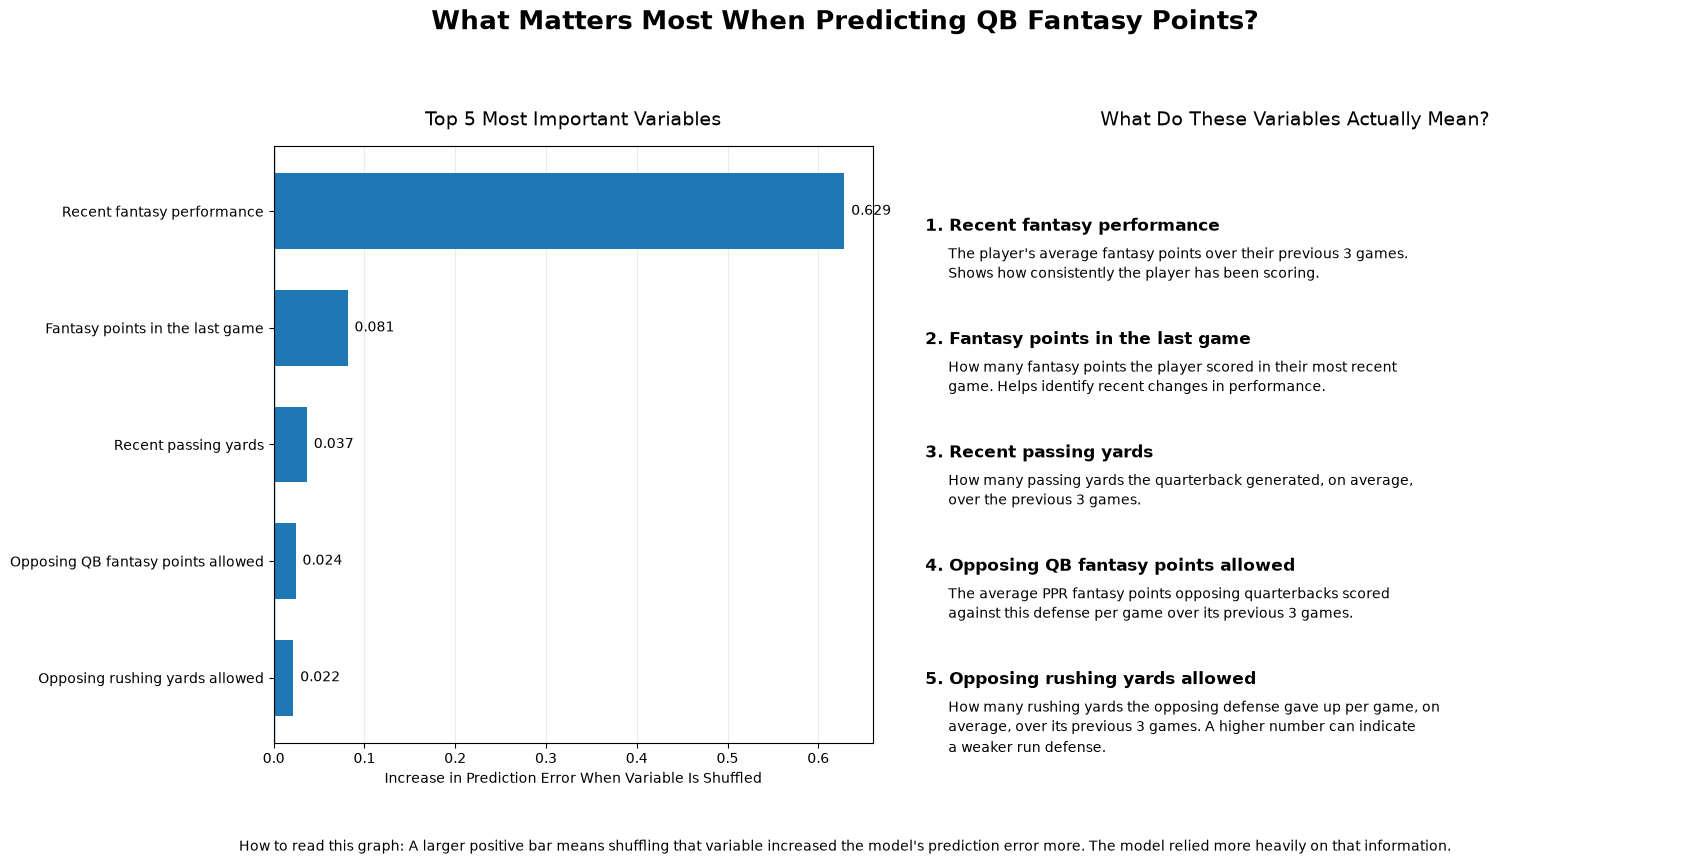

Saved: qb_detailed_feature_importance.png


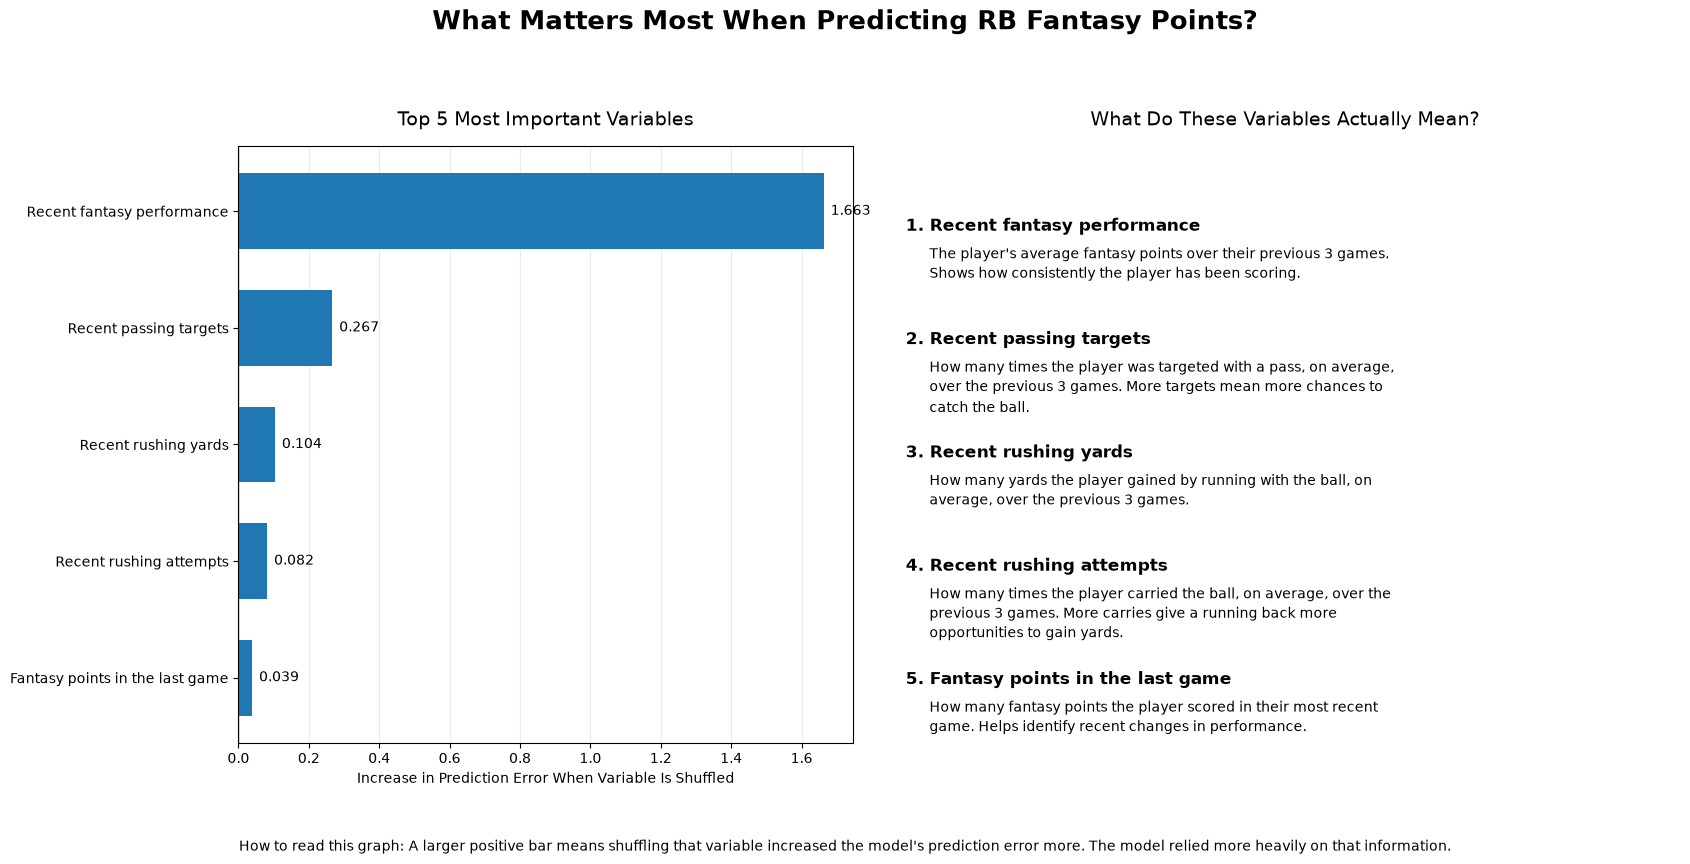

Saved: rb_detailed_feature_importance.png


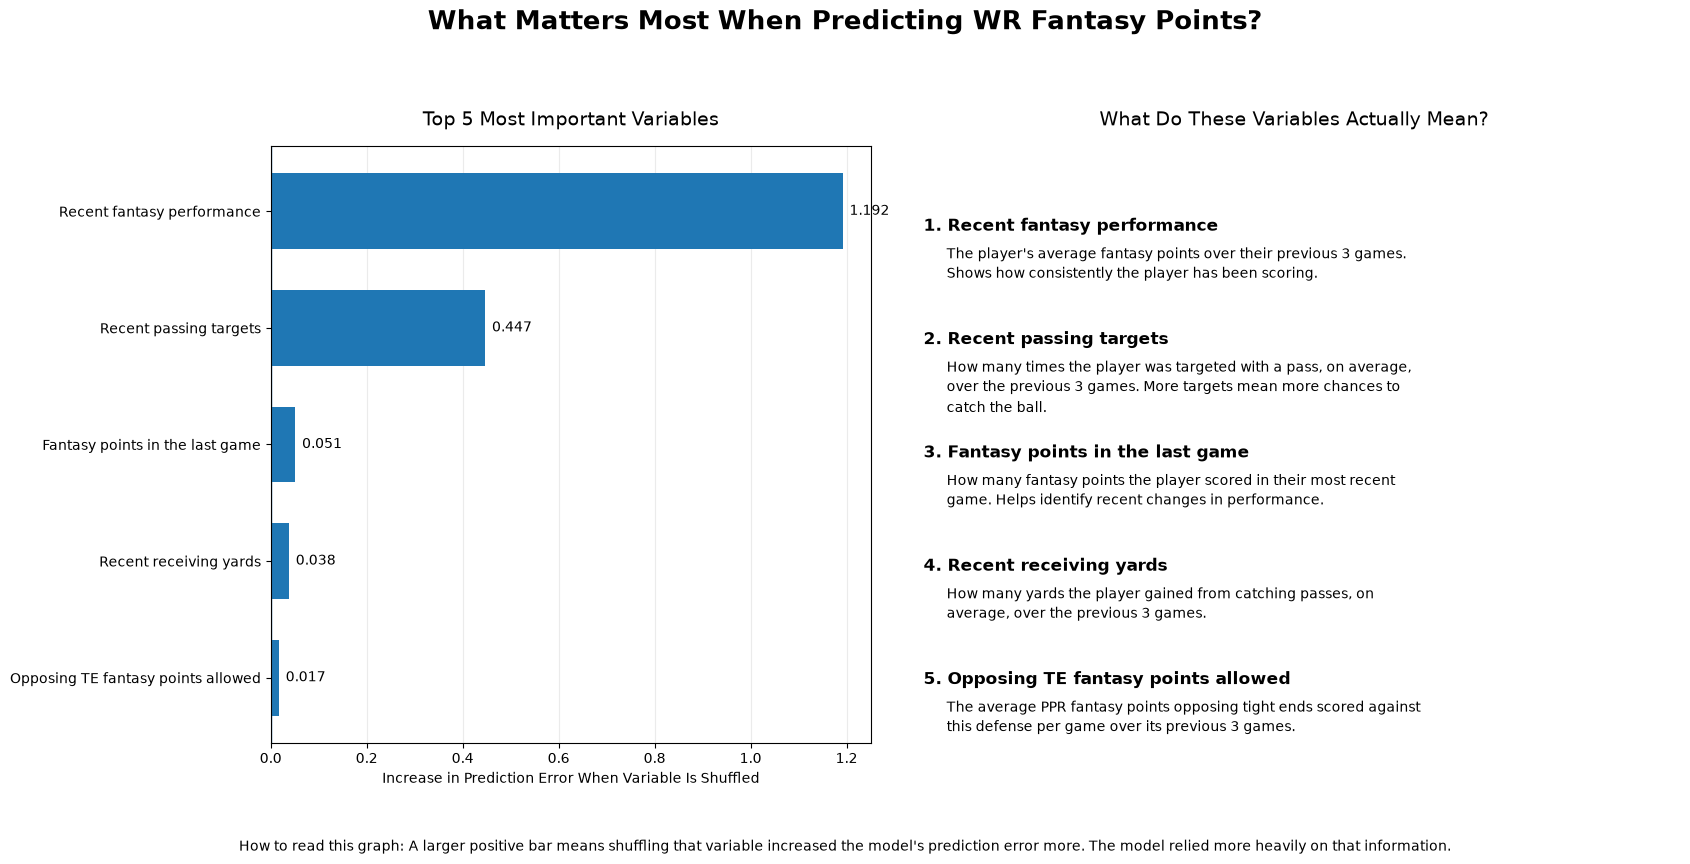

Saved: wr_detailed_feature_importance.png


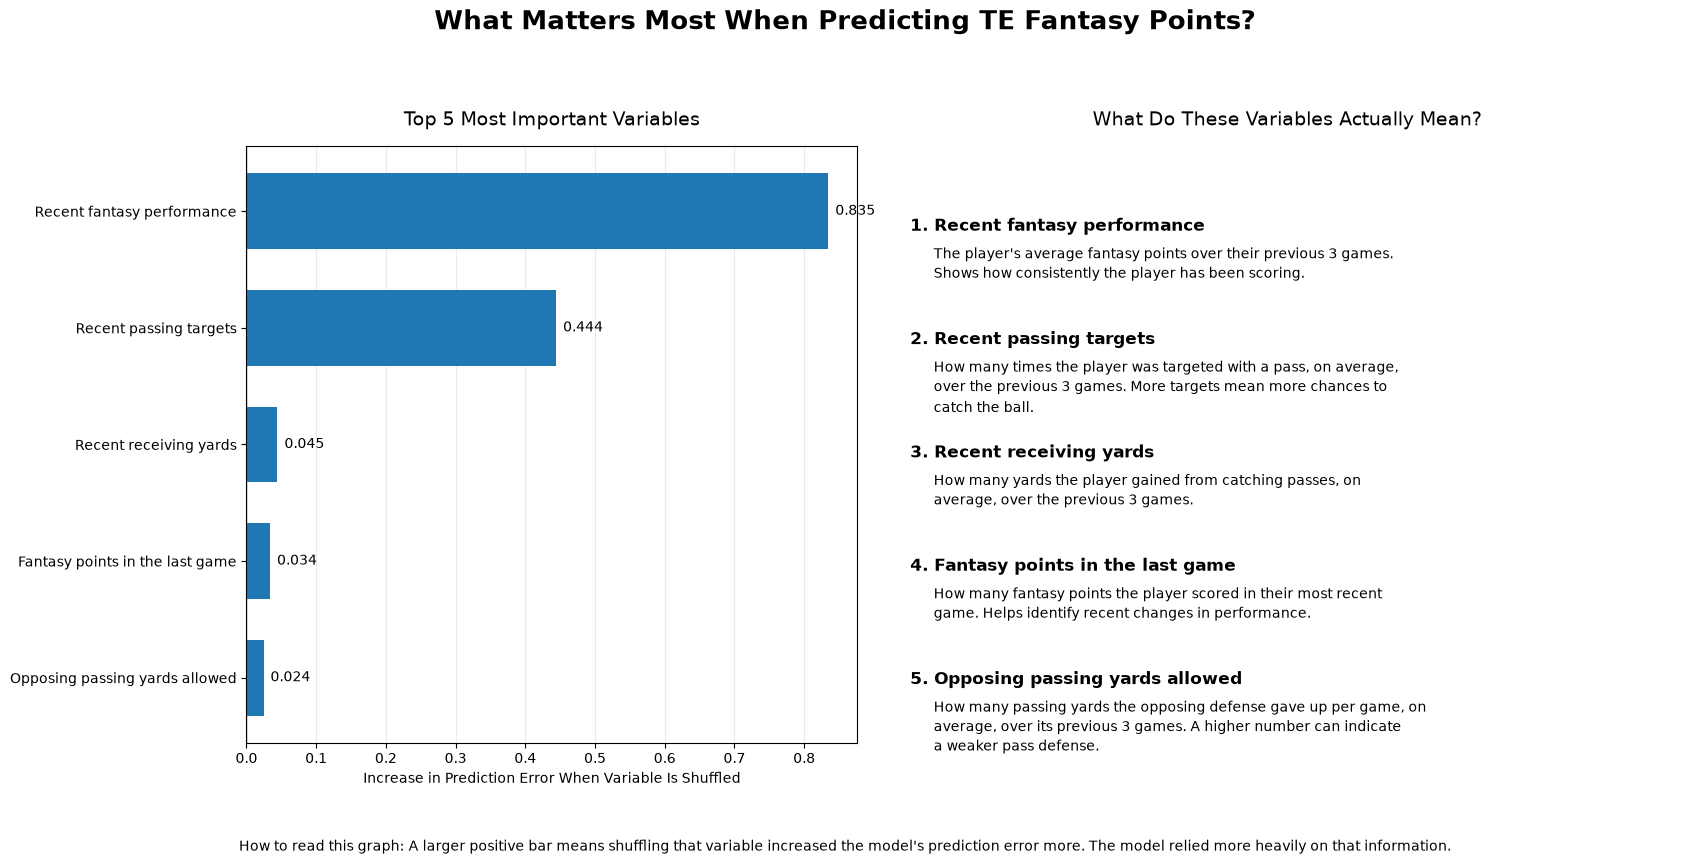

Saved: te_detailed_feature_importance.png


In [54]:

import matplotlib.pyplot as plt
import textwrap

# Translate technical variable names into football-friendly names
variable_info = {
    "average_previous_3_games": (
        "Recent fantasy performance",
        "The player's average fantasy points over their previous 3 games. "
        "Shows how consistently the player has been scoring."
    ),
    "previous_week_fantasy_points": (
        "Fantasy points in the last game",
        "How many fantasy points the player scored in their most recent game. "
        "Helps identify recent changes in performance."
    ),
    "average_previous_3_targets": (
        "Recent passing targets",
        "How many times the player was targeted with a pass, on average, "
        "over the previous 3 games. More targets mean more chances to catch the ball."
    ),
    "average_previous_3_carries": (
        "Recent rushing attempts",
        "How many times the player carried the ball, on average, over the previous "
        "3 games. More carries give a running back more opportunities to gain yards."
    ),
    "average_previous_3_attempts": (
        "Recent quarterback pass attempts",
        "How many passes the player attempted, on average, over the previous "
        "3 games. More attempts create more opportunities to gain passing yards."
    ),
    "average_previous_3_completions": (
        "Recent completed passes",
        "How many passes the player completed, on average, over the previous "
        "3 games. Completed passes help generate passing yards and touchdowns."
    ),
    "average_previous_3_receptions": (
        "Recent catches",
        "How many passes the player caught, on average, over the previous "
        "3 games. In PPR scoring, every catch earns an additional fantasy point."
    ),
    "average_previous_3_receiving_yards": (
        "Recent receiving yards",
        "How many yards the player gained from catching passes, on average, "
        "over the previous 3 games."
    ),
    "average_previous_3_rushing_yards": (
        "Recent rushing yards",
        "How many yards the player gained by running with the ball, on average, "
        "over the previous 3 games."
    ),
    "average_previous_3_passing_yards": (
        "Recent passing yards",
        "How many passing yards the quarterback generated, on average, "
        "over the previous 3 games."
    ),
    "average_previous_3_passing_tds": (
        "Recent passing touchdowns",
        "How many touchdown passes the player threw, on average, "
        "over the previous 3 games."
    ),
    "average_previous_3_receiving_tds": (
        "Recent receiving touchdowns",
        "How many touchdowns the player scored by catching passes, on average, "
        "over the previous 3 games."
    ),
    "average_previous_3_rushing_tds": (
        "Recent rushing touchdowns",
        "How many touchdowns the player scored by running the ball, on average, "
        "over the previous 3 games."
    ),
    "average_previous_3_passing_interceptions": (
        "Recent interceptions thrown",
        "How many interceptions the quarterback threw, on average, "
        "over the previous 3 games. Interceptions lower fantasy scoring."
    ),
    "average_previous_3_passing_yards_allowed": (
        "Opposing passing yards allowed",
        "How many passing yards the opposing defense gave up per game, on average, "
        "over its previous 3 games. A higher number can indicate a weaker pass defense."
    ),
    "average_previous_3_passing_tds_allowed": (
        "Opposing passing touchdowns allowed",
        "How many passing touchdowns the opposing defense allowed per game, on average, "
        "over its previous 3 games."
    ),
    "average_previous_3_passing_attempts_allowed": (
        "Opposing pass attempts faced",
        "How many passes opposing offenses attempted against the defense, "
        "on average, over its previous 3 games."
    ),
    "average_previous_3_passing_completions_allowed": (
        "Opposing completed passes allowed",
        "How many passes opposing offenses completed against the defense, "
        "on average, over its previous 3 games."
    ),
    "average_previous_3_rushing_yards_allowed": (
        "Opposing rushing yards allowed",
        "How many rushing yards the opposing defense gave up per game, on average, "
        "over its previous 3 games. A higher number can indicate a weaker run defense."
    ),
    "average_previous_3_rushing_tds_allowed": (
        "Opposing rushing touchdowns allowed",
        "How many rushing touchdowns the opposing defense gave up per game, "
        "on average, over its previous 3 games."
    ),
    "average_previous_3_receiving_yards_allowed": (
        "Opposing receiving yards allowed",
        "How many receiving yards the opposing defense gave up per game, on average, "
        "over its previous 3 games."
    ),
    "average_previous_3_receiving_tds_allowed": (
        "Opposing receiving touchdowns allowed",
        "How many receiving touchdowns the opposing defense gave up per game, "
        "on average, over its previous 3 games."
    ),
    "average_previous_3_receptions_allowed": (
        "Opposing catches allowed",
        "How many passes opposing players caught against the defense per game, "
        "on average, over its previous 3 games."
    ),
    "average_previous_3_targets_allowed": (
        "Opposing passing targets faced",
        "How many times opposing offenses targeted receivers against the defense, "
        "on average, over its previous 3 games."
    ),
    "average_previous_3_qb_points_allowed": (
        "Opposing QB fantasy points allowed",
        "The average PPR fantasy points opposing quarterbacks scored against this "
        "defense per game over its previous 3 games."
    ),
    "average_previous_3_rb_points_allowed": (
        "Opposing RB fantasy points allowed",
        "The average PPR fantasy points opposing running backs scored against this "
        "defense per game over its previous 3 games."
    ),
    "average_previous_3_wr_points_allowed": (
        "Opposing WR fantasy points allowed",
        "The average PPR fantasy points opposing wide receivers scored against this "
        "defense per game over its previous 3 games."
    ),
    "average_previous_3_te_points_allowed": (
        "Opposing TE fantasy points allowed",
        "The average PPR fantasy points opposing tight ends scored against this "
        "defense per game over its previous 3 games."
    )
}

def get_variable_info(feature):
    if feature in variable_info:
        return variable_info[feature]

    # Fallback for any variables not listed above
    readable_name = feature.replace("average_previous_3_", "")
    readable_name = readable_name.replace("_", " ").title()
    return readable_name, "A statistic used by the model to help predict weekly fantasy points."


positions = ["QB", "RB", "WR", "TE"]

for position in positions:

    # Get the five most important variables for this position
    top_five = (
        position_importance_results[position]
        .head(5)
        .to_dicts()
    )

    # Reverse the rows so the most important appears at the top
    top_five = top_five[::-1]

    names = []
    values = []
    explanations = []

    for item in top_five:
        feature_name = item["Feature"]
        importance_value = item["Importance"]

        display_name, explanation = get_variable_info(feature_name)

        names.append(display_name)
        values.append(importance_value)
        explanations.append(explanation)

    # Create a larger, two-column poster-ready figure
    fig, (ax, explanation_ax) = plt.subplots(
        1, 2,
        figsize=(17, 9),
        gridspec_kw={"width_ratios": [1.05, 1.35]}
    )

    fig.suptitle(
        f"What Matters Most When Predicting {position} Fantasy Points?",
        fontsize=19,
        fontweight="bold",
        y=0.97
    )

    # LEFT: Importance graph
    y_positions = range(len(names))

    bars = ax.barh(y_positions, values, height=0.65)

    ax.set_yticks(list(y_positions))
    ax.set_yticklabels(names, fontsize=10)
    ax.set_xlabel(
        "Increase in Prediction Error When Variable Is Shuffled",
        fontsize=10
    )
    ax.set_title("Top 5 Most Important Variables", fontsize=14, pad=15)

    ax.axvline(0, linewidth=1)
    ax.grid(axis="x", alpha=0.25)
    ax.set_axisbelow(True)

    # Show the importance value beside each bar
    for bar, value in zip(bars, values):
        if value >= 0:
            ax.annotate(
                f"{value:.3f}",
                (value, bar.get_y() + bar.get_height() / 2),
                xytext=(5, 0),
                textcoords="offset points",
                va="center",
                fontsize=10
            )
        else:
            ax.annotate(
                f"{value:.3f}",
                (value, bar.get_y() + bar.get_height() / 2),
                xytext=(-5, 0),
                textcoords="offset points",
                ha="right",
                va="center",
                fontsize=10
            )

    # RIGHT: Explain each variable in simple terms
    explanation_ax.axis("off")
    explanation_ax.set_title(
        "What Do These Variables Actually Mean?",
        fontsize=14,
        pad=15
    )

    for i, (name, explanation) in enumerate(
        zip(names[::-1], explanations[::-1])
    ):
        y = 0.88 - i * 0.19

        explanation_ax.text(
            0.02, y,
            f"{i + 1}. {name}",
            fontsize=12,
            fontweight="bold",
            transform=explanation_ax.transAxes,
            va="top"
        )

        wrapped_explanation = textwrap.fill(explanation, width=65)

        explanation_ax.text(
            0.05, y - 0.045,
            wrapped_explanation,
            fontsize=10,
            transform=explanation_ax.transAxes,
            va="top",
            linespacing=1.4
        )

    # Explanation of the graph itself
    fig.text(
        0.5, 0.035,
        "How to read this graph: A larger positive bar means shuffling that "
        "variable increased the model's prediction error more. "
        "The model relied more heavily on that information.",
        ha="center",
        fontsize=10,
        wrap=True
    )

    plt.tight_layout(rect=[0, 0.09, 1, 0.92])

    filename = f"{position.lower()}_detailed_feature_importance.png"

    plt.savefig(
        filename,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

    print(f"Saved: {filename}")


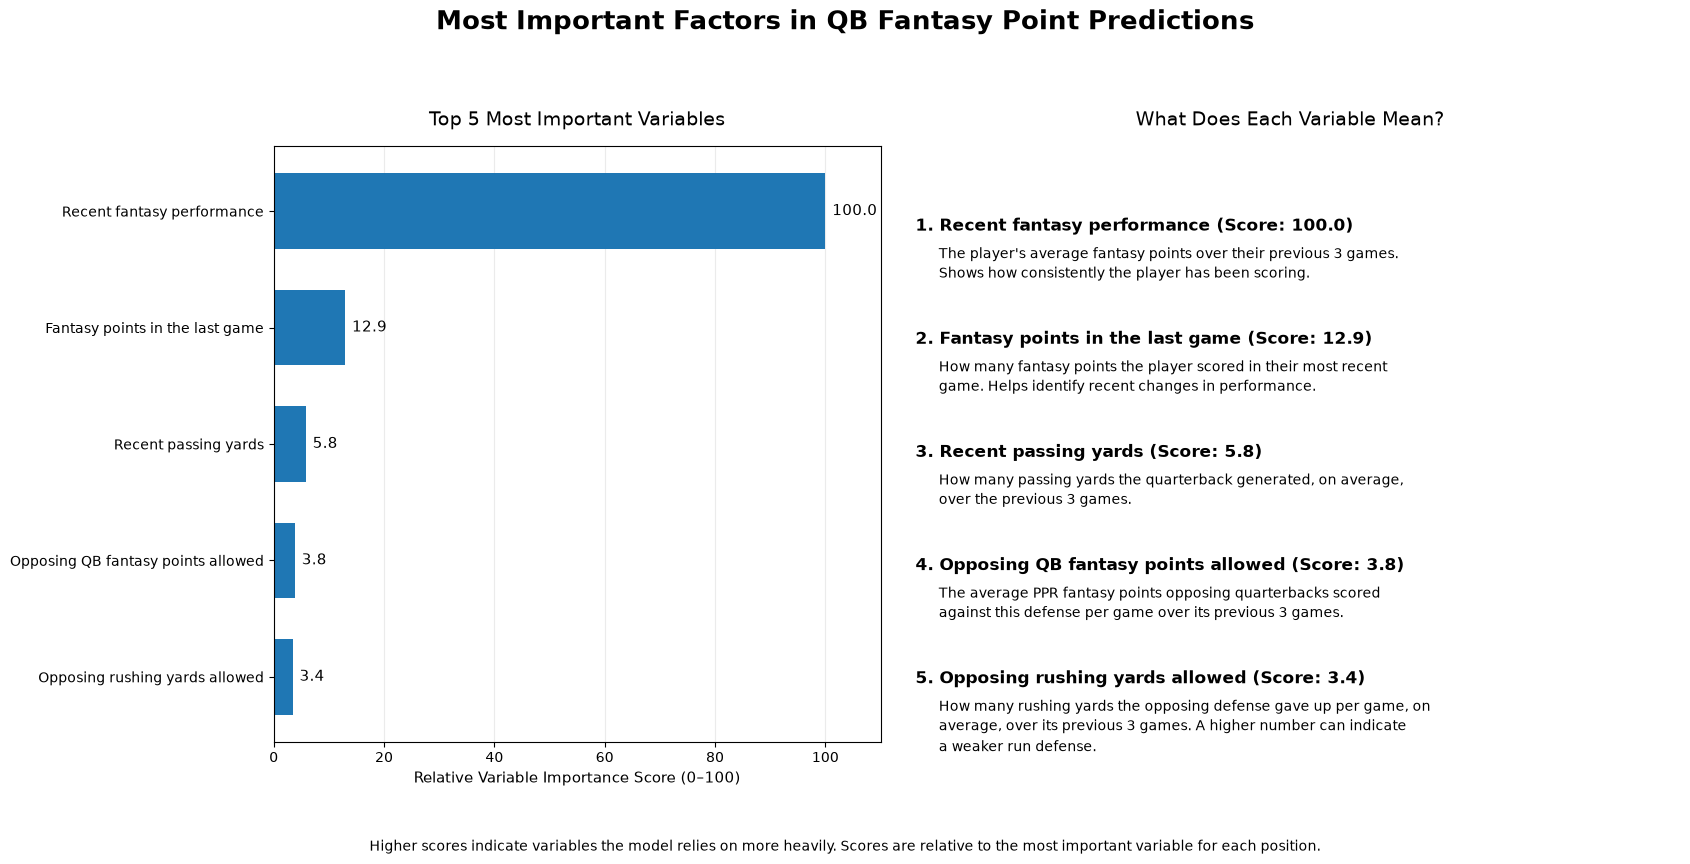


QB VARIABLE IMPORTANCE SCORES
Recent fantasy performance: 100.0/100
Fantasy points in the last game: 12.9/100
Recent passing yards: 5.8/100
Opposing QB fantasy points allowed: 3.8/100
Opposing rushing yards allowed: 3.4/100


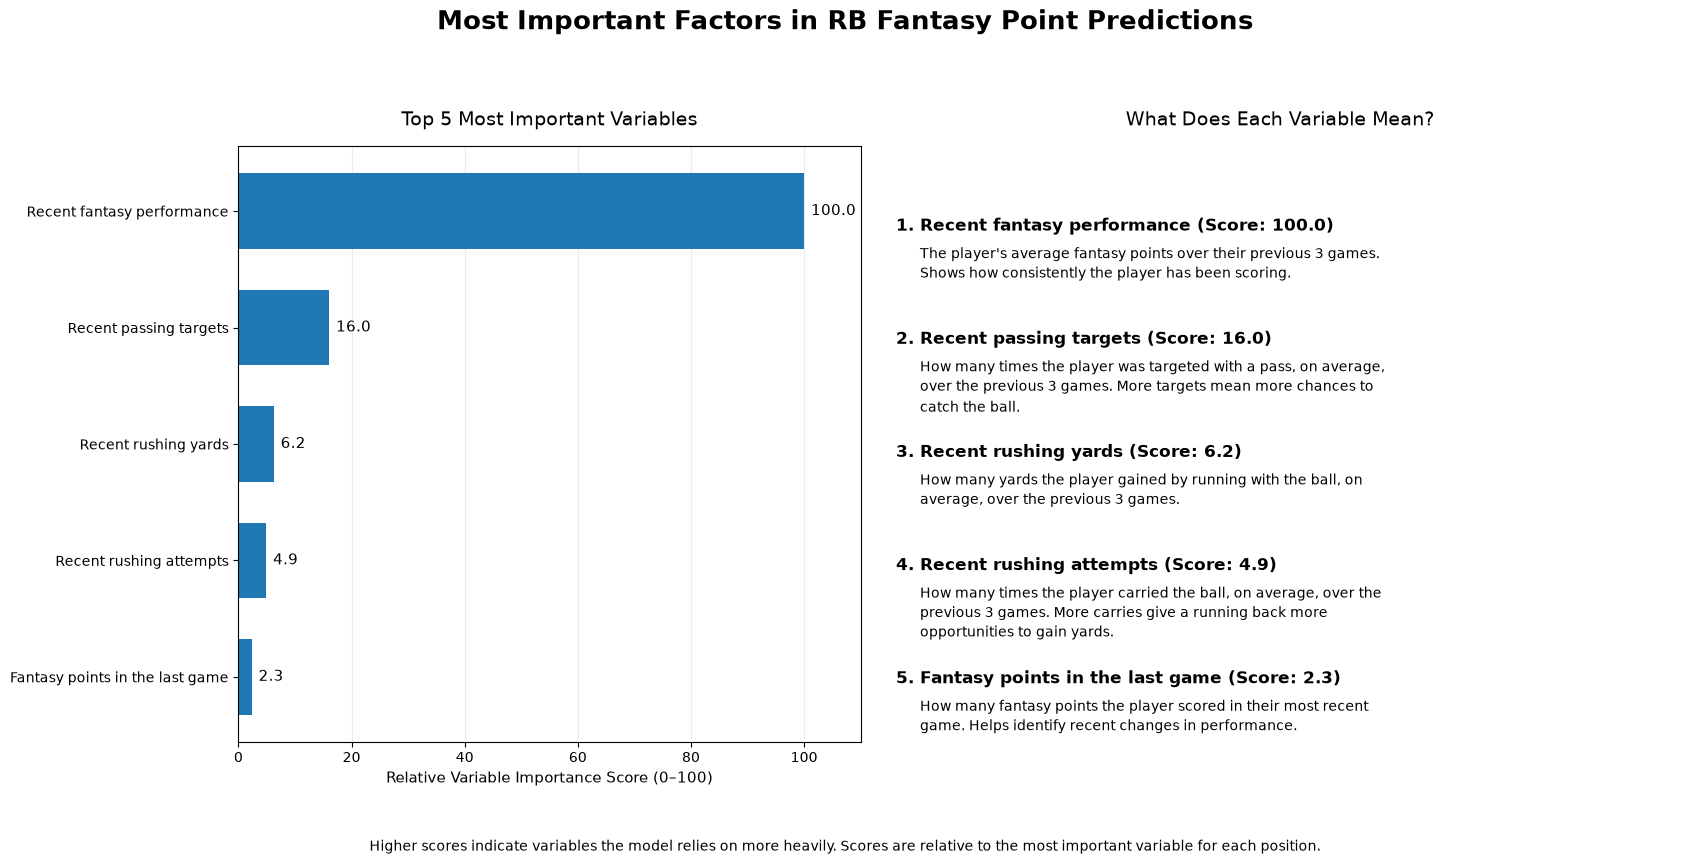


RB VARIABLE IMPORTANCE SCORES
Recent fantasy performance: 100.0/100
Recent passing targets: 16.0/100
Recent rushing yards: 6.2/100
Recent rushing attempts: 4.9/100
Fantasy points in the last game: 2.3/100


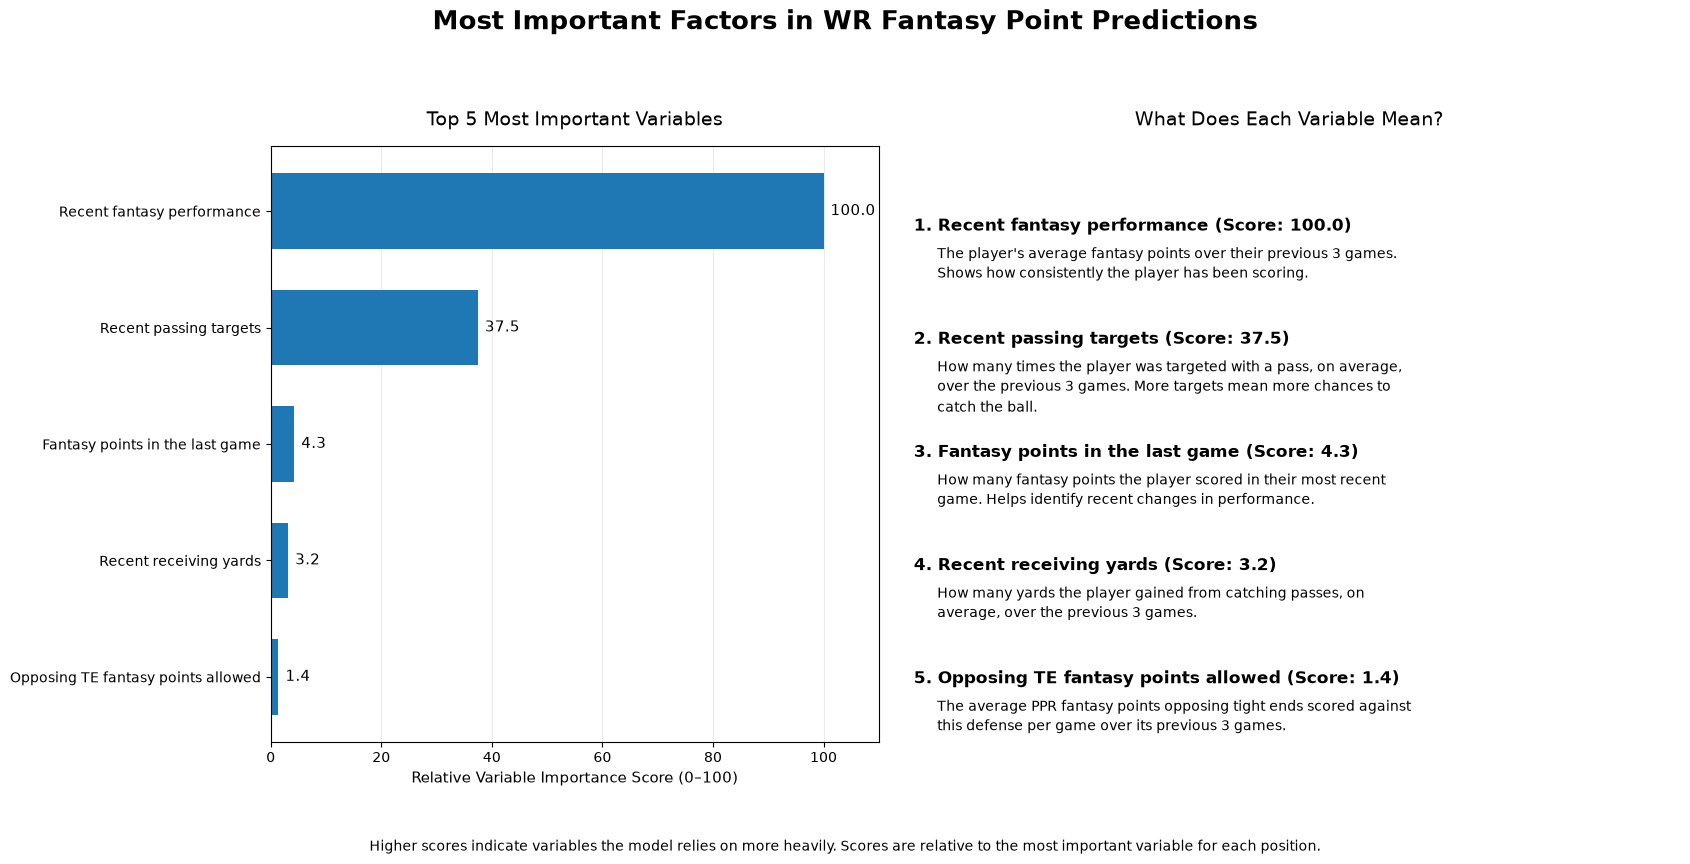


WR VARIABLE IMPORTANCE SCORES
Recent fantasy performance: 100.0/100
Recent passing targets: 37.5/100
Fantasy points in the last game: 4.3/100
Recent receiving yards: 3.2/100
Opposing TE fantasy points allowed: 1.4/100


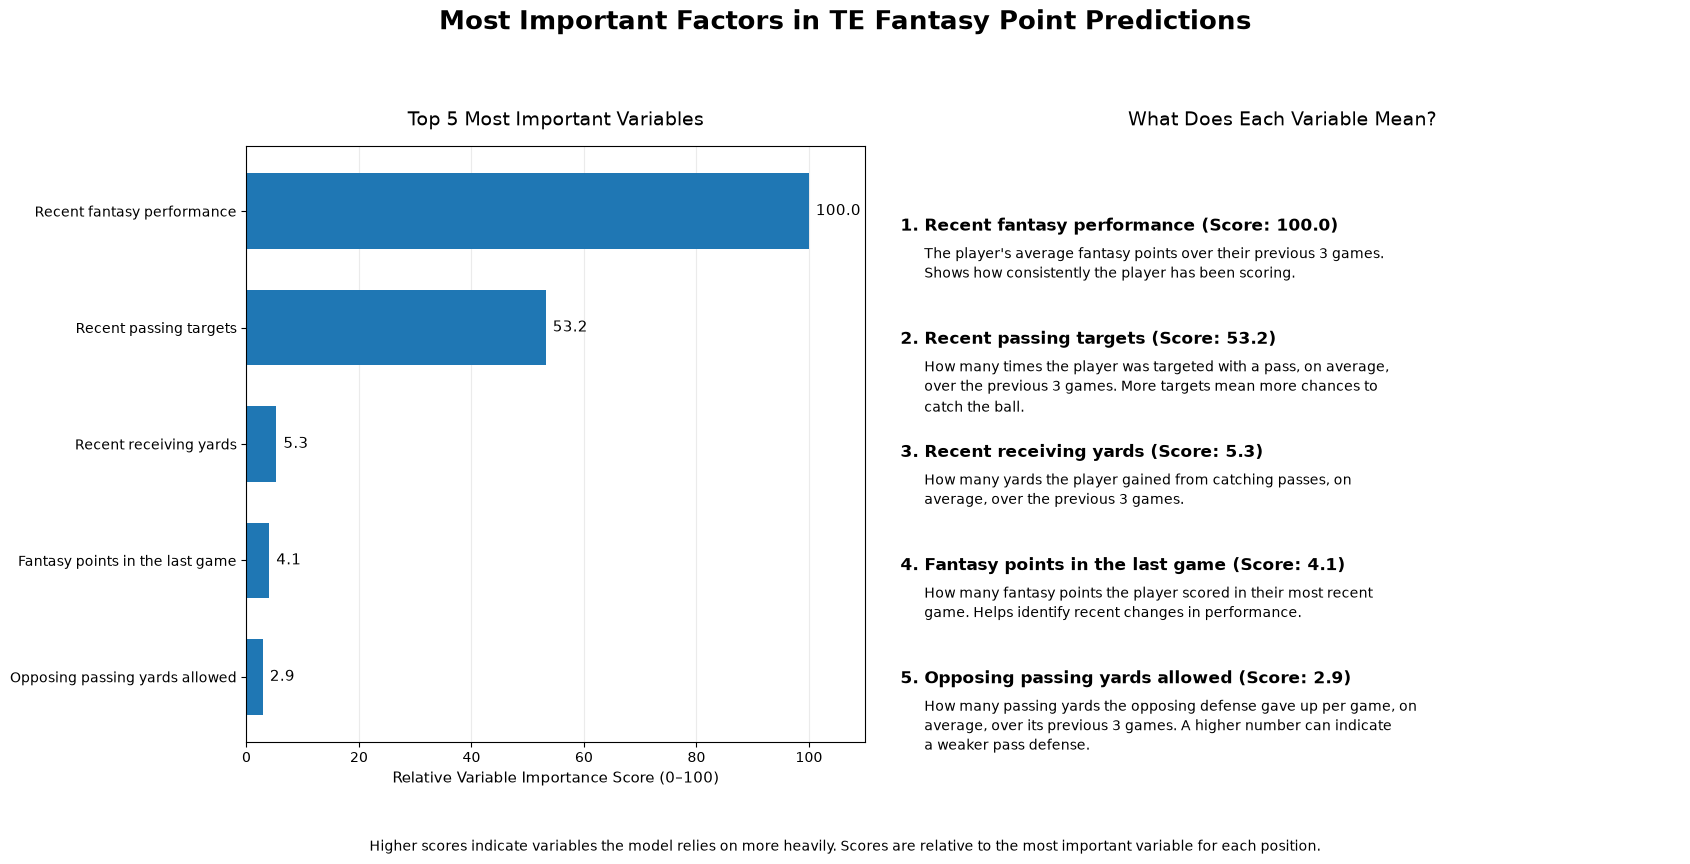


TE VARIABLE IMPORTANCE SCORES
Recent fantasy performance: 100.0/100
Recent passing targets: 53.2/100
Recent receiving yards: 5.3/100
Fantasy points in the last game: 4.1/100
Opposing passing yards allowed: 2.9/100


In [55]:

import matplotlib.pyplot as plt
import textwrap

positions = ["QB", "RB", "WR", "TE"]

for position in positions:

    # Get the five most important variables
    top_five = (
        position_importance_results[position]
        .sort("Importance", descending=True)
        .head(5)
        .to_dicts()
    )

    # Use the highest importance value as the reference
    highest_importance = top_five[0]["Importance"]

    names = []
    scores = []
    explanations = []

    for item in top_five:
        feature = item["Feature"]
        importance = item["Importance"]

        display_name, explanation = get_variable_info(feature)

        # Convert importance into a relative 0-100 score
        score = (
            (importance / highest_importance) * 100
            if highest_importance > 0 else 0
        )

        names.append(display_name)
        scores.append(score)
        explanations.append(explanation)

    # Reverse order for graph display
    names = names[::-1]
    scores = scores[::-1]
    explanations = explanations[::-1]

    fig, (ax, explanation_ax) = plt.subplots(
        1, 2,
        figsize=(17, 9),
        gridspec_kw={"width_ratios": [1.05, 1.35]}
    )

    fig.suptitle(
        f"Most Important Factors in {position} Fantasy Point Predictions",
        fontsize=19,
        fontweight="bold",
        y=0.97
    )

    # LEFT: Importance scores
    y_positions = range(len(names))

    bars = ax.barh(
        y_positions,
        scores,
        height=0.65
    )

    ax.set_yticks(list(y_positions))
    ax.set_yticklabels(names, fontsize=10)

    ax.set_xlabel(
        "Relative Variable Importance Score (0–100)",
        fontsize=11
    )

    ax.set_title(
        "Top 5 Most Important Variables",
        fontsize=14,
        pad=15
    )

    ax.set_xlim(0, 110)
    ax.grid(axis="x", alpha=0.25)
    ax.set_axisbelow(True)

    for bar, score in zip(bars, scores):
        ax.annotate(
            f"{score:.1f}",
            (score, bar.get_y() + bar.get_height() / 2),
            xytext=(5, 0),
            textcoords="offset points",
            va="center",
            fontsize=11
        )

    # RIGHT: Simple explanations
    explanation_ax.axis("off")

    explanation_ax.set_title(
        "What Does Each Variable Mean?",
        fontsize=14,
        pad=15
    )

    for i, (name, explanation, score) in enumerate(
        zip(names[::-1], explanations[::-1], scores[::-1])
    ):

        y = 0.88 - i * 0.19

        explanation_ax.text(
            0.02, y,
            f"{i + 1}. {name} (Score: {score:.1f})",
            fontsize=12,
            fontweight="bold",
            transform=explanation_ax.transAxes,
            va="top"
        )

        explanation_ax.text(
            0.05, y - 0.045,
            textwrap.fill(explanation, width=65),
            fontsize=10,
            transform=explanation_ax.transAxes,
            va="top",
            linespacing=1.4
        )

    fig.text(
        0.5, 0.035,
        "Higher scores indicate variables the model relies on more heavily. "
        "Scores are relative to the most important variable for each position.",
        ha="center",
        fontsize=10
    )

    plt.tight_layout(rect=[0, 0.09, 1, 0.92])

    filename = f"{position.lower()}_importance_scores.png"

    plt.savefig(
        filename,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

    print(f"\n{position} VARIABLE IMPORTANCE SCORES")

    for name, score in zip(names[::-1], scores[::-1]):
        print(f"{name}: {score:.1f}/100")


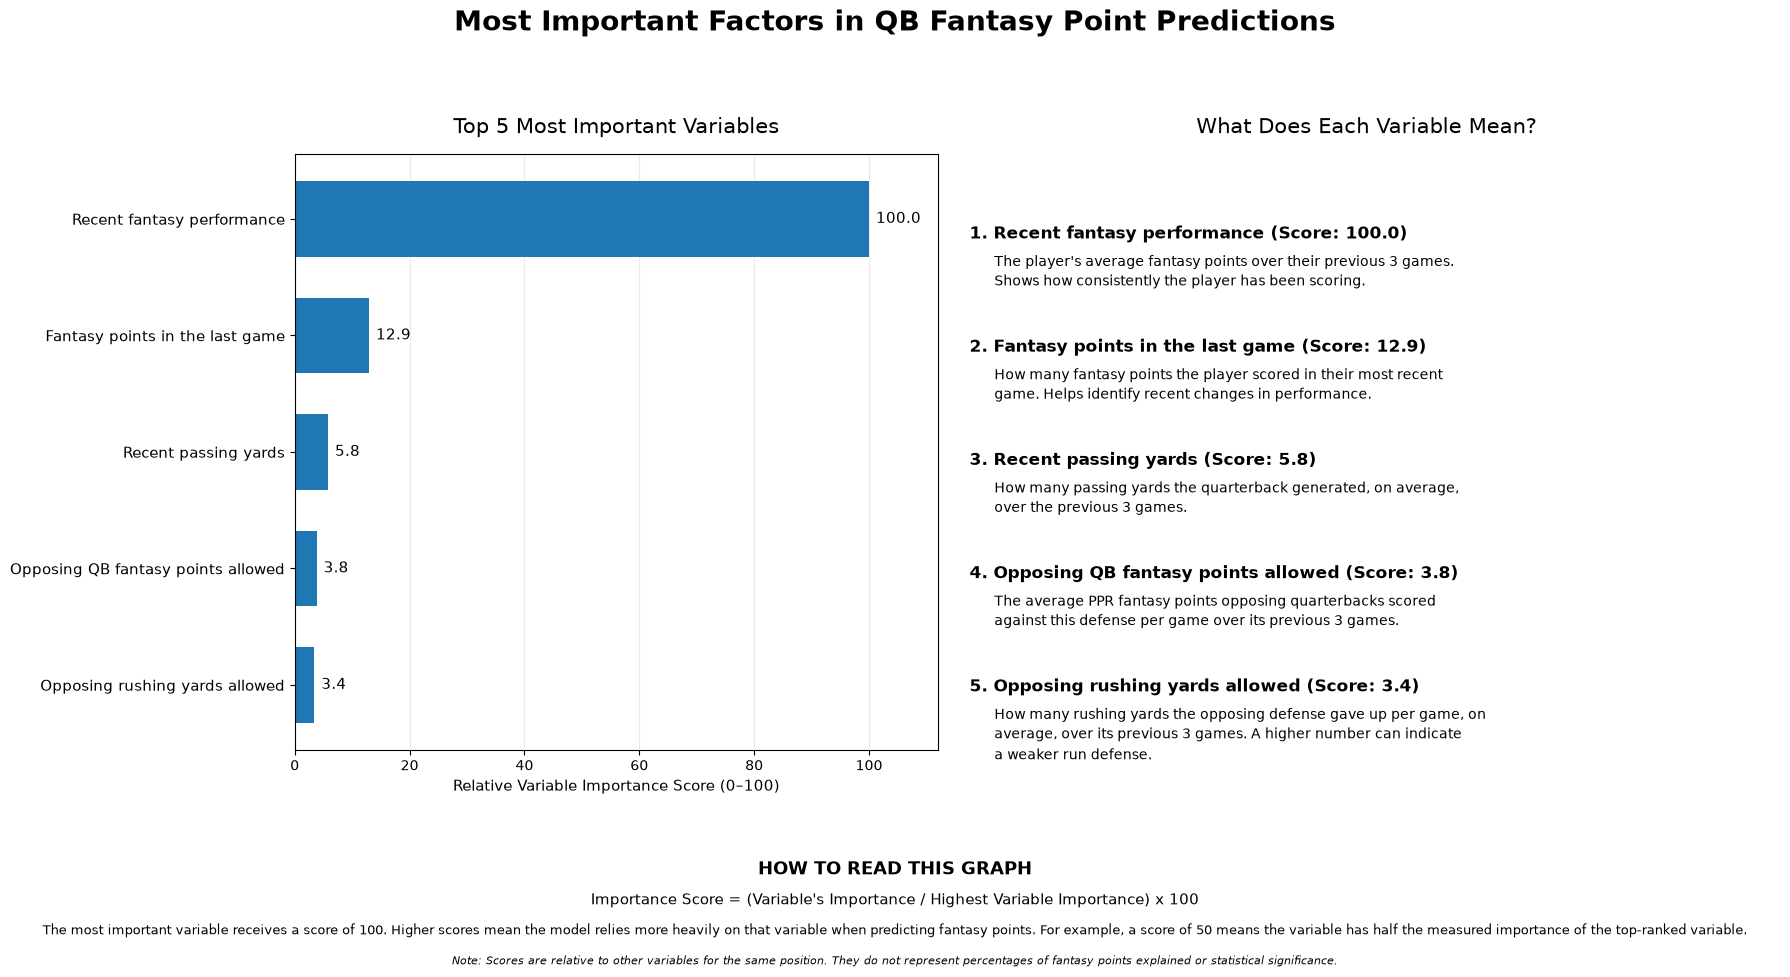


QB VARIABLE IMPORTANCE SCORES
Recent fantasy performance: 100.0/100
Fantasy points in the last game: 12.9/100
Recent passing yards: 5.8/100
Opposing QB fantasy points allowed: 3.8/100
Opposing rushing yards allowed: 3.4/100
Saved: qb_importance_scores.png


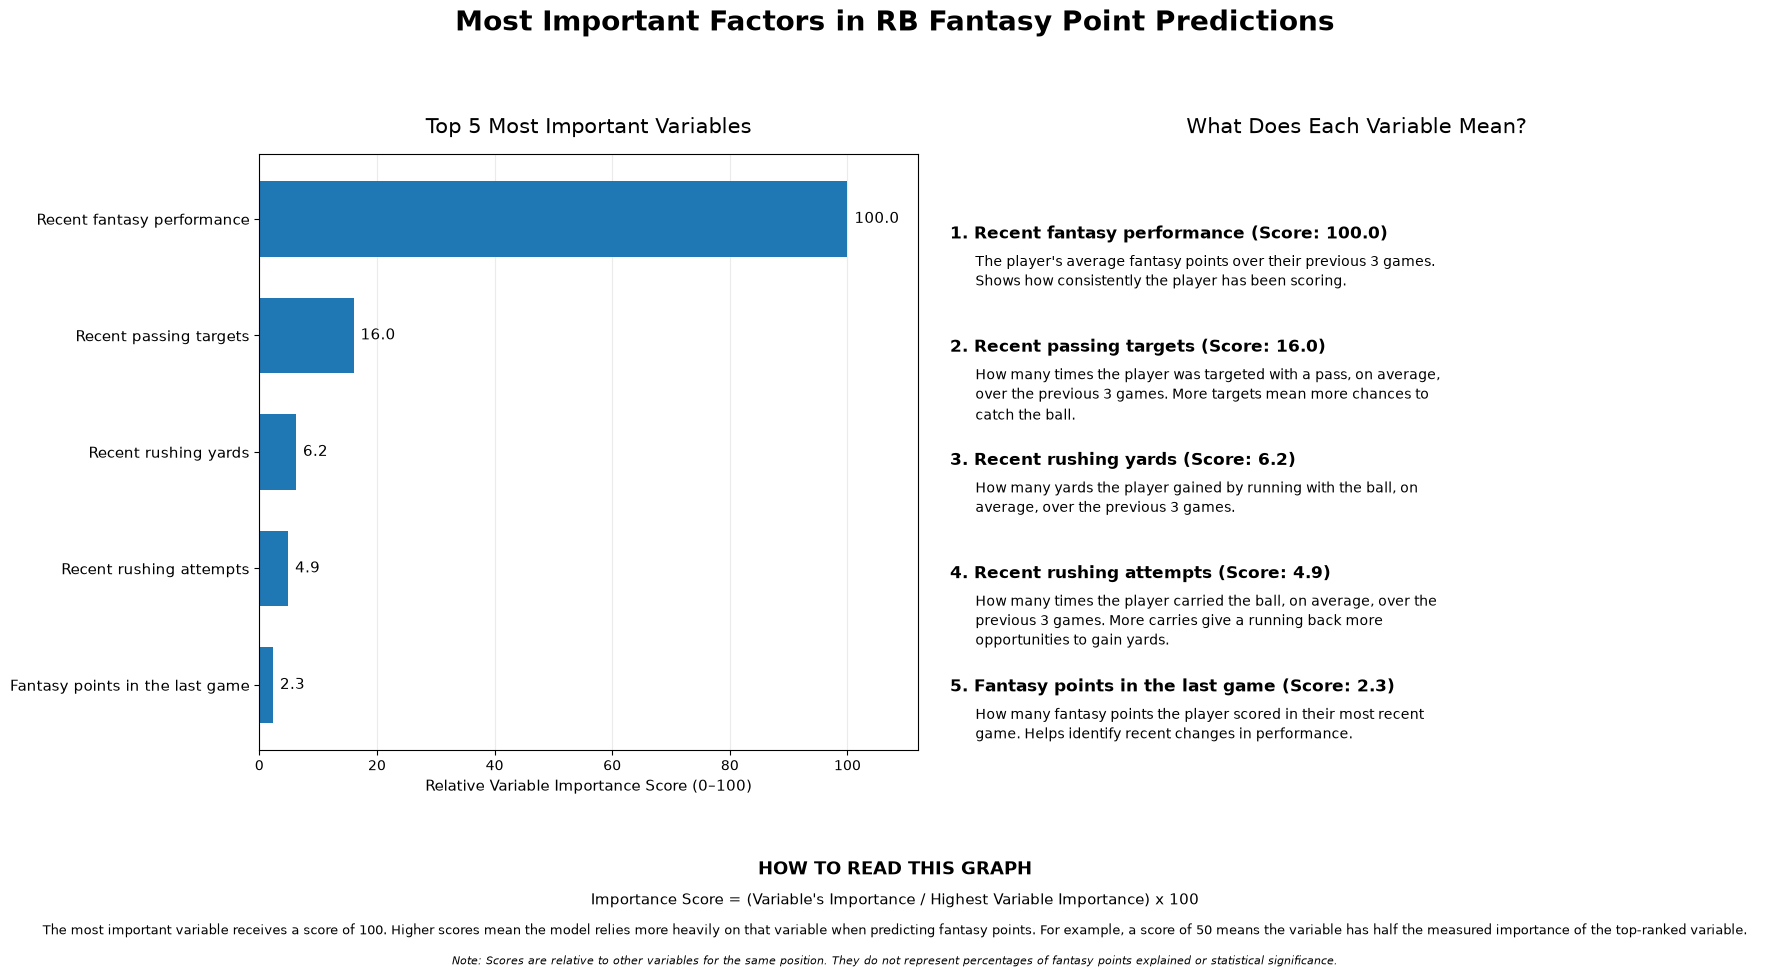


RB VARIABLE IMPORTANCE SCORES
Recent fantasy performance: 100.0/100
Recent passing targets: 16.0/100
Recent rushing yards: 6.2/100
Recent rushing attempts: 4.9/100
Fantasy points in the last game: 2.3/100
Saved: rb_importance_scores.png


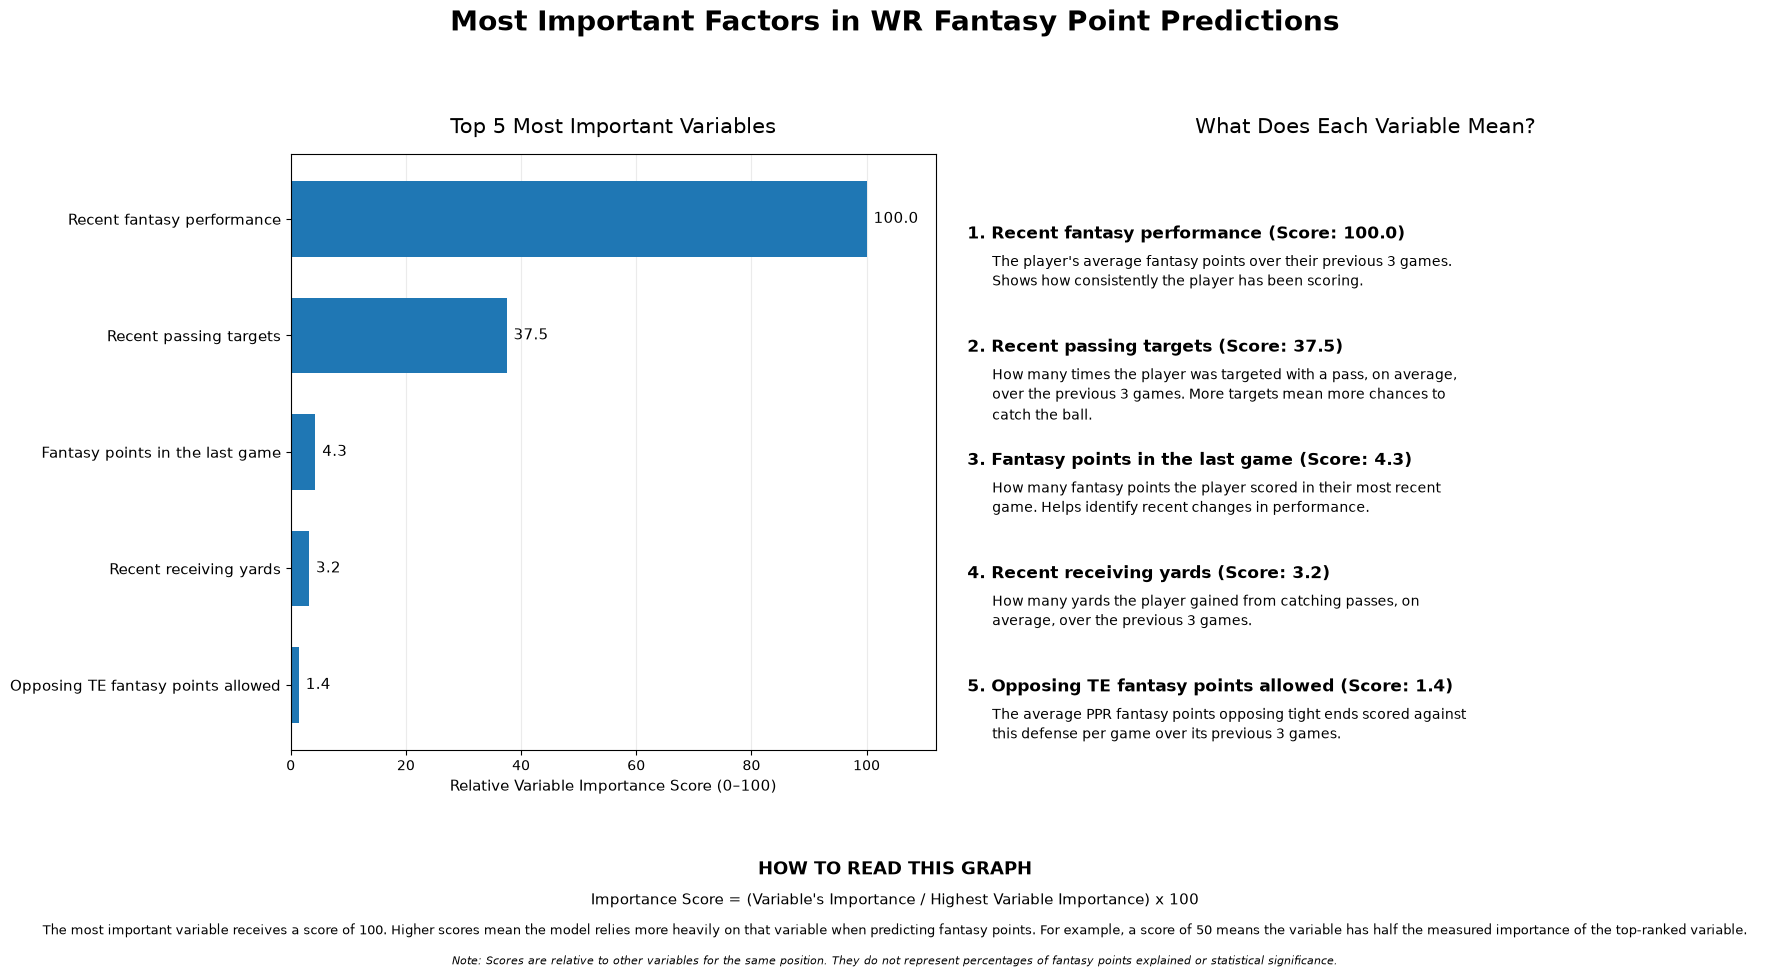


WR VARIABLE IMPORTANCE SCORES
Recent fantasy performance: 100.0/100
Recent passing targets: 37.5/100
Fantasy points in the last game: 4.3/100
Recent receiving yards: 3.2/100
Opposing TE fantasy points allowed: 1.4/100
Saved: wr_importance_scores.png


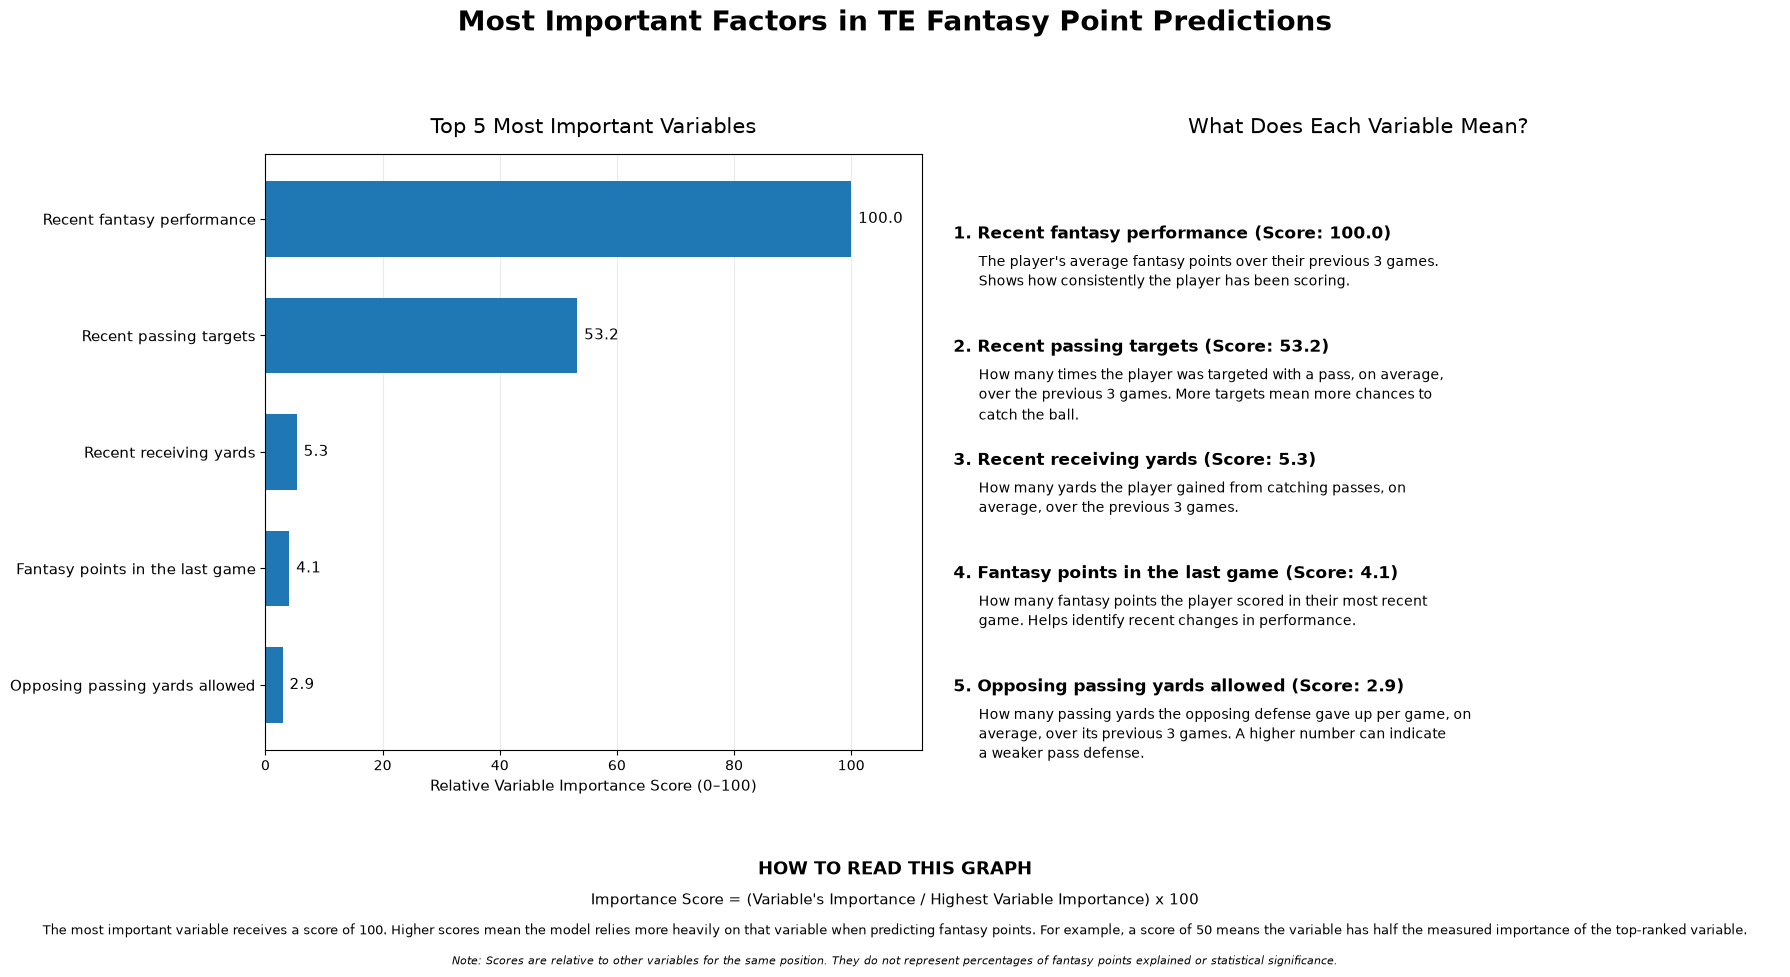


TE VARIABLE IMPORTANCE SCORES
Recent fantasy performance: 100.0/100
Recent passing targets: 53.2/100
Recent receiving yards: 5.3/100
Fantasy points in the last game: 4.1/100
Opposing passing yards allowed: 2.9/100
Saved: te_importance_scores.png


In [56]:

import matplotlib.pyplot as plt
import textwrap

positions = ["QB", "RB", "WR", "TE"]

for position in positions:

    # Get the five most important variables
    top_five = (
        position_importance_results[position]
        .sort("Importance", descending=True)
        .head(5)
        .to_dicts()
    )

    # Highest importance value becomes the reference score of 100
    highest_importance = top_five[0]["Importance"]

    names = []
    scores = []
    explanations = []

    for item in top_five:
        feature = item["Feature"]
        importance = item["Importance"]

        display_name, explanation = get_variable_info(feature)

        # Calculate relative importance score
        score = (
            (importance / highest_importance) * 100
            if highest_importance > 0 else 0
        )

        names.append(display_name)
        scores.append(score)
        explanations.append(explanation)

    # Reverse order so most important appears at the top
    names = names[::-1]
    scores = scores[::-1]
    explanations = explanations[::-1]

    # Create graph and explanation layout
    fig, (ax, explanation_ax) = plt.subplots(
        1, 2,
        figsize=(18, 10),
        gridspec_kw={"width_ratios": [1.05, 1.35]}
    )

    fig.suptitle(
        f"Most Important Factors in {position} Fantasy Point Predictions",
        fontsize=20,
        fontweight="bold",
        y=0.97
    )

    # -----------------------------------
    # LEFT SIDE: VARIABLE IMPORTANCE GRAPH
    # -----------------------------------

    y_positions = range(len(names))

    bars = ax.barh(
        y_positions,
        scores,
        height=0.65
    )

    ax.set_yticks(list(y_positions))
    ax.set_yticklabels(names, fontsize=11)

    ax.set_xlabel(
        "Relative Variable Importance Score (0–100)",
        fontsize=11
    )

    ax.set_title(
        "Top 5 Most Important Variables",
        fontsize=15,
        pad=15
    )

    ax.set_xlim(0, 112)
    ax.grid(axis="x", alpha=0.25)
    ax.set_axisbelow(True)

    # Display importance scores beside bars
    for bar, score in zip(bars, scores):
        ax.annotate(
            f"{score:.1f}",
            (score, bar.get_y() + bar.get_height() / 2),
            xytext=(5, 0),
            textcoords="offset points",
            va="center",
            fontsize=11
        )

    # -----------------------------------
    # RIGHT SIDE: SIMPLE VARIABLE EXPLANATIONS
    # -----------------------------------

    explanation_ax.axis("off")

    explanation_ax.set_title(
        "What Does Each Variable Mean?",
        fontsize=15,
        pad=15
    )

    for i, (name, explanation, score) in enumerate(
        zip(names[::-1], explanations[::-1], scores[::-1])
    ):

        y = 0.88 - i * 0.19

        explanation_ax.text(
            0.02, y,
            f"{i + 1}. {name} (Score: {score:.1f})",
            fontsize=12,
            fontweight="bold",
            transform=explanation_ax.transAxes,
            va="top"
        )

        explanation_ax.text(
            0.05, y - 0.045,
            textwrap.fill(explanation, width=65),
            fontsize=10,
            transform=explanation_ax.transAxes,
            va="top",
            linespacing=1.4
        )

    # -----------------------------------
    # BOTTOM: EXPLANATION OF IMPORTANCE SCORES
    # -----------------------------------

    fig.text(
        0.5, 0.105,
        "HOW TO READ THIS GRAPH",
        ha="center",
        fontsize=13,
        fontweight="bold"
    )

    fig.text(
        0.5, 0.075,
        "Importance Score = (Variable's Importance / Highest Variable "
        "Importance) x 100",
        ha="center",
        fontsize=11
    )

    fig.text(
        0.5, 0.045,
        "The most important variable receives a score of 100. Higher scores "
        "mean the model relies more heavily on that variable when predicting "
        "fantasy points. For example, a score of 50 means the variable has "
        "half the measured importance of the top-ranked variable.",
        ha="center",
        fontsize=9,
        wrap=True
    )

    fig.text(
        0.5, 0.015,
        "Note: Scores are relative to other variables for the same position. "
        "They do not represent percentages of fantasy points explained or "
        "statistical significance.",
        ha="center",
        fontsize=8,
        style="italic"
    )

    # Final formatting and save
    plt.tight_layout(rect=[0, 0.17, 1, 0.92])

    filename = f"{position.lower()}_importance_scores.png"

    plt.savefig(
        filename,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

    # Print rankings in notebook
    print(f"\n{position} VARIABLE IMPORTANCE SCORES")

    for name, score in zip(names[::-1], scores[::-1]):
        print(f"{name}: {score:.1f}/100")

    print(f"Saved: {filename}")
